In [57]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [58]:
import pandas as pd
import numpy as np
from pathlib import Path

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment ready!")

Pandas: 3.1.0
NumPy: 2.5.4
Environment ready!


In [59]:
DATA_PATH = Path(r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw")

csv_files = list(DATA_PATH.glob("*.csv"))

print("Total CSV files found:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files found: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [60]:
datasets = {}

for file in csv_files:
    name = file.stem
    datasets[name] = pd.read_csv(file)

    print(f"{name}: {datasets[name].shape}")

olist_customers_dataset: (99441, 5)
olist_geolocation_dataset: (1000163, 5)
olist_orders_dataset: (99441, 8)
olist_order_items_dataset: (112650, 7)
olist_order_payments_dataset: (103886, 5)
olist_order_reviews_dataset: (99224, 7)
olist_products_dataset: (32951, 9)
olist_sellers_dataset: (3095, 4)
product_category_name_translation: (71, 2)


In [61]:
for name, df in datasets.items():
    print("\nDataset:", name)
    print("Rows and columns:", df.shape)
    print("Column names:", df.columns.tolist())
    print("-" * 60)


Dataset: olist_customers_dataset
Rows and columns: (99441, 5)
Column names: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
------------------------------------------------------------

Dataset: olist_geolocation_dataset
Rows and columns: (1000163, 5)
Column names: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']
------------------------------------------------------------

Dataset: olist_orders_dataset
Rows and columns: (99441, 8)
Column names: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
------------------------------------------------------------

Dataset: olist_order_items_dataset
Rows and columns: (112650, 7)
Column names: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_valu

In [62]:
missing_report = {}

for name, df in datasets.items():

    missing = df.isnull().sum()

    missing_report[name] = {
        "Total Missing Values": missing.sum(),
        "Columns With Missing Values": (missing > 0).sum()
    }

missing_df = pd.DataFrame(missing_report).T

missing_df

,Total Missing Values,Columns With Missing Values
olist_customers_dataset,0,0
olist_geolocation_dataset,0,0
olist_orders_dataset,4908,3
olist_order_items_dataset,0,0
olist_order_payments_dataset,0,0
olist_order_reviews_dataset,145903,2
olist_products_dataset,2448,8
olist_sellers_dataset,0,0
product_category_name_translation,0,0


In [63]:
duplicate_report = {}

for name, df in datasets.items():

    duplicate_report[name] = df.duplicated().sum()

duplicate_df = pd.DataFrame(
    duplicate_report.items(),
    columns=["Dataset", "Duplicate Rows"]
)

duplicate_df

,Dataset,Duplicate Rows
0,olist_customers_dataset,0
1,olist_geolocation_dataset,261831
2,olist_orders_dataset,0
3,olist_order_items_dataset,0
4,olist_order_payments_dataset,0
5,olist_order_reviews_dataset,0
6,olist_products_dataset,0
7,olist_sellers_dataset,0
8,product_category_name_translation,0


In [64]:
for name, df in datasets.items():

    print("\nDataset:", name)
    print(df.dtypes)
    print("=" * 50)


Dataset: olist_customers_dataset
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Dataset: olist_geolocation_dataset
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Dataset: olist_orders_dataset
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Dataset: olist_order_items_dataset
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price

In [65]:
for name, df in datasets.items():

    missing = df.isnull().sum()

    missing = missing[missing > 0]

    if len(missing) > 0:

        print("\nDataset:", name)
        print("-" * 45)

        for column, count in missing.items():

            percentage = (count / len(df)) * 100

            print(
                f"{column}: {count} missing "
                f"({percentage:.2f}%)"
            )


Dataset: olist_orders_dataset
---------------------------------------------
order_approved_at: 160 missing (0.16%)
order_delivered_carrier_date: 1783 missing (1.79%)
order_delivered_customer_date: 2965 missing (2.98%)

Dataset: olist_order_reviews_dataset
---------------------------------------------
review_comment_title: 87656 missing (88.34%)
review_comment_message: 58247 missing (58.70%)

Dataset: olist_products_dataset
---------------------------------------------
product_category_name: 610 missing (1.85%)
product_name_lenght: 610 missing (1.85%)
product_description_lenght: 610 missing (1.85%)
product_photos_qty: 610 missing (1.85%)
product_weight_g: 2 missing (0.01%)
product_length_cm: 2 missing (0.01%)
product_height_cm: 2 missing (0.01%)
product_width_cm: 2 missing (0.01%)


In [66]:
geo = datasets["olist_geolocation_dataset"]

print("Original shape:", geo.shape)

print(
    "Exact duplicate rows:",
    geo.duplicated().sum()
)

print(
    "Unique postal code prefixes:",
    geo["geolocation_zip_code_prefix"].nunique()
)

print(
    "Rows after removing exact duplicates:",
    geo.drop_duplicates().shape
)

Original shape: (1000163, 5)
Exact duplicate rows: 261831
Unique postal code prefixes: 19015
Rows after removing exact duplicates: (738332, 5)


In [67]:
geo_duplicates = geo[
    geo.duplicated(keep=False)
]

geo_duplicates.head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [68]:
for name, df in datasets.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:

        print("\nDataset:", name)
        print("-" * 50)

        for column, count in missing.items():

            percentage = (count / len(df)) * 100

            print(
                f"{column}: {count} missing "
                f"({percentage:.2f}%)"
            )
            


Dataset: olist_orders_dataset
--------------------------------------------------
order_approved_at: 160 missing (0.16%)
order_delivered_carrier_date: 1783 missing (1.79%)
order_delivered_customer_date: 2965 missing (2.98%)

Dataset: olist_order_reviews_dataset
--------------------------------------------------
review_comment_title: 87656 missing (88.34%)
review_comment_message: 58247 missing (58.70%)

Dataset: olist_products_dataset
--------------------------------------------------
product_category_name: 610 missing (1.85%)
product_name_lenght: 610 missing (1.85%)
product_description_lenght: 610 missing (1.85%)
product_photos_qty: 610 missing (1.85%)
product_weight_g: 2 missing (0.01%)
product_length_cm: 2 missing (0.01%)
product_height_cm: 2 missing (0.01%)
product_width_cm: 2 missing (0.01%)


In [69]:
geo = datasets["olist_geolocation_dataset"]

print("Original rows:", len(geo))

print("Exact duplicate rows:",
      geo.duplicated().sum())

print("Unique postal prefixes:",
      geo["geolocation_zip_code_prefix"].nunique())

print("Rows after removing exact duplicates:",
      len(geo.drop_duplicates()))

Original rows: 1000163
Exact duplicate rows: 261831
Unique postal prefixes: 19015
Rows after removing exact duplicates: 738332


In [70]:
geo_duplicates = geo[
    geo.duplicated(keep=False)
]

geo_duplicates.head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
6,1047,-23.546273,-46.641225,sao paulo,SP
7,1013,-23.546923,-46.634264,sao paulo,SP
8,1029,-23.543769,-46.634278,sao paulo,SP
9,1011,-23.547640,-46.636032,sao paulo,SP
10,1013,-23.547325,-46.634184,sao paulo,SP
13,1012,-23.548946,-46.634671,sao paulo,SP
15,1046,-23.546081,-46.644820,sao paulo,SP


In [71]:
# Create a separate copy
geo_cleaned = geo.copy()

# Remove exact duplicate records
geo_cleaned = geo_cleaned.drop_duplicates()

# Reset row index
geo_cleaned = geo_cleaned.reset_index(drop=True)

# Validate cleaning
print("Original rows:", len(geo))
print("Cleaned rows:", len(geo_cleaned))

print(
    "Remaining duplicates:",
    geo_cleaned.duplicated().sum()
)

Original rows: 1000163
Cleaned rows: 738332
Remaining duplicates: 0


In [72]:
# Create a separate copy
geo_cleaned = geo.copy()

# Remove exact duplicate records
geo_cleaned = geo_cleaned.drop_duplicates()

# Reset row index
geo_cleaned = geo_cleaned.reset_index(drop=True)

# Validate cleaning
print("Original rows:", len(geo))
print("Cleaned rows:", len(geo_cleaned))

print(
    "Remaining duplicates:",
    geo_cleaned.duplicated().sum()
)

Original rows: 1000163
Cleaned rows: 738332
Remaining duplicates: 0


In [73]:
for name, df in datasets.items():

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print("\n", name)
        print(missing)


 olist_orders_dataset
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

 olist_order_reviews_dataset
review_comment_title      87656
review_comment_message    58247
dtype: int64

 olist_products_dataset
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [74]:
orders = datasets["olist_orders_dataset"]

for column in [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]:
    print("\nMissing values in:", column)

    print(
        orders.loc[
            orders[column].isnull(),
            "order_status"
        ].value_counts()
    )


Missing values in: order_approved_at
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing values in: order_delivered_carrier_date
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Missing values in: order_delivered_customer_date
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [75]:
products = datasets["olist_products_dataset"]

missing_products = products[
    products["product_category_name"].isnull()
]

print("Products with missing category:",
      len(missing_products))

missing_products.head(10)

Products with missing category: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [76]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

missing_dimensions = products[
    products[dimension_columns].isnull().any(axis=1)
]

missing_dimensions

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [77]:
reviews = datasets["olist_order_reviews_dataset"]

print("Total reviews:", len(reviews))

print(
    "Missing both title and message:",
    (
        reviews["review_comment_title"].isnull()
        & reviews["review_comment_message"].isnull()
    ).sum()
)

print(
    "Ratings available:",
    reviews["review_score"].notnull().sum()
)

Total reviews: 99224
Missing both title and message: 56518
Ratings available: 99224


In [78]:
orders = datasets["olist_orders_dataset"]

delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isnull())
]

print("Delivered orders missing delivery date:",
      len(delivered_missing_date))

delivered_missing_date

Delivered orders missing delivery date: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,28-11-2017 17:44,28-11-2017 17:56,30-11-2017 18:12,NaN,18-12-2017 00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,20-06-2018 06:58,20-06-2018 07:19,25-06-2018 08:05,NaN,16-07-2018 00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,01-07-2018 17:05,01-07-2018 17:15,03-07-2018 13:57,NaN,30-07-2018 00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,01-07-2018 22:05,01-07-2018 22:15,03-07-2018 13:57,NaN,30-07-2018 00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,01-07-2018 21:14,01-07-2018 21:29,03-07-2018 09:28,NaN,24-07-2018 00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,25-05-2017 23:22,25-05-2017 23:30,NaN,NaN,23-06-2017 00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,08-06-2018 12:09,08-06-2018 12:36,12-06-2018 14:10,NaN,26-06-2018 00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,27-06-2018 16:09,27-06-2018 16:29,03-07-2018 19:26,NaN,19-07-2018 00:00


In [79]:
products = datasets["olist_products_dataset"]

dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

incomplete_products = products[
    products[dimension_columns].isnull().any(axis=1)
]

incomplete_products

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [80]:
catalogue_columns = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

no_catalogue_info = products[
    products[catalogue_columns].isnull().all(axis=1)
]

print("Products missing all catalogue information:",
      len(no_catalogue_info))

no_catalogue_info.head()

Products missing all catalogue information: 610


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0


In [81]:
items = datasets["olist_order_items_dataset"]

print("Negative product prices:",
      (items["price"] < 0).sum())

print("Zero product prices:",
      (items["price"] == 0).sum())

print("Negative freight values:",
      (items["freight_value"] < 0).sum())

Negative product prices: 0
Zero product prices: 0
Negative freight values: 0


In [82]:
products = datasets["olist_products_dataset"]

dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in dimension_columns:
    print(col, "zero values:", (products[col] == 0).sum())
    print(col, "negative values:", (products[col] < 0).sum())

product_weight_g zero values: 4
product_weight_g negative values: 0
product_length_cm zero values: 0
product_length_cm negative values: 0
product_height_cm zero values: 0
product_height_cm negative values: 0
product_width_cm zero values: 0
product_width_cm negative values: 0


In [83]:
reviews = datasets["olist_order_reviews_dataset"]

print("Review scores:")
print(reviews["review_score"].value_counts().sort_index())

print("Invalid review scores:",
      (~reviews["review_score"].between(1, 5)).sum())

Review scores:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Invalid review scores: 0


In [84]:
zero_weight_products = products[
    products["product_weight_g"] == 0
]

zero_weight_products[
    [
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
]

,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0


In [85]:
for name, df in datasets.items():
    print("\nDataset:", name)
    print(df.dtypes)


Dataset: olist_customers_dataset
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Dataset: olist_geolocation_dataset
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Dataset: olist_orders_dataset
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Dataset: olist_order_items_dataset
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price

In [86]:
orders = datasets["olist_orders_dataset"]

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        errors="coerce"
    )

orders[date_columns].dtypes

C:\Users\acer\AppData\Local\Temp\ipykernel_9708\1124742209.py:12: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  orders[col] = pd.to_datetime(


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [87]:
orders[date_columns].isnull().sum()

order_purchase_timestamp         59810
order_approved_at                59793
order_delivered_carrier_date     62109
order_delivered_customer_date    63087
order_estimated_delivery_date        0
dtype: int64

In [88]:
for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        format="%d-%m-%Y %H:%M",
        errors="coerce"
    )

orders[date_columns].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [89]:
orders[date_columns].isnull().sum()

order_purchase_timestamp         59810
order_approved_at                59793
order_delivered_carrier_date     62109
order_delivered_customer_date    63087
order_estimated_delivery_date        0
dtype: int64

In [90]:
orders = datasets["olist_orders_dataset"]

for col in date_columns:
    print("\nColumn:", col)
    print(orders[col].head(5))


Column: order_purchase_timestamp
0   2017-02-10 10:56:00
1                   NaT
2   2018-08-08 08:38:00
3                   NaT
4                   NaT
Name: order_purchase_timestamp, dtype: datetime64[us]

Column: order_approved_at
0   2017-02-10 11:07:00
1                   NaT
2   2018-08-08 08:55:00
3                   NaT
4                   NaT
Name: order_approved_at, dtype: datetime64[us]

Column: order_delivered_carrier_date
0   2017-04-10 19:55:00
1                   NaT
2   2018-08-08 13:50:00
3                   NaT
4                   NaT
Name: order_delivered_carrier_date, dtype: datetime64[us]

Column: order_delivered_customer_date
0   2017-10-10 21:25:00
1   2018-07-08 15:27:00
2                   NaT
3   2017-02-12 00:28:00
4                   NaT
Name: order_delivered_customer_date, dtype: datetime64[us]

Column: order_estimated_delivery_date
0   2017-10-18
1   2018-08-13
2   2018-09-04
3   2017-12-15
4   2018-02-26
Name: order_estimated_delivery_date, dtype: dateti

In [91]:
orders_raw = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\olist_orders_dataset.csv"
)

orders_raw[date_columns].head(10)

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,02-10-2017 10:56,02-10-2017 11:07,04-10-2017 19:55,10-10-2017 21:25,18-10-2017 00:00
1,24-07-2018 20:41,26-07-2018 03:24,26-07-2018 14:31,07-08-2018 15:27,13-08-2018 00:00
2,08-08-2018 08:38,08-08-2018 08:55,08-08-2018 13:50,17-08-2018 18:06,04-09-2018 00:00
3,18-11-2017 19:28,18-11-2017 19:45,22-11-2017 13:39,02-12-2017 00:28,15-12-2017 00:00
4,13-02-2018 21:18,13-02-2018 22:20,14-02-2018 19:46,16-02-2018 18:17,26-02-2018 00:00
5,09-07-2017 21:57,09-07-2017 22:10,11-07-2017 14:58,26-07-2017 10:57,01-08-2017 00:00
6,11-04-2017 12:22,13-04-2017 13:25,NaN,NaN,09-05-2017 00:00
7,16-05-2017 13:10,16-05-2017 13:22,22-05-2017 10:07,26-05-2017 12:55,07-06-2017 00:00
8,23-01-2017 18:29,25-01-2017 02:50,26-01-2017 14:16,02-02-2017 14:08,06-03-2017 00:00
9,29-07-2017 11:55,29-07-2017 12:05,10-08-2017 19:45,16-08-2017 17:14,23-08-2017 00:00


In [92]:
print(orders_raw["order_purchase_timestamp"].iloc[0])
print(orders_raw["order_approved_at"].iloc[0])

02-10-2017 10:56
02-10-2017 11:07


In [93]:
orders = orders_raw.copy()

for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        format="%d-%m-%Y %H:%M",
        errors="coerce"
    )

In [94]:
print("Date column types:")
print(orders[date_columns].dtypes)

print("\nMissing dates:")
print(orders[date_columns].isnull().sum())

Date column types:
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Missing dates:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [95]:
for col in date_columns:
    print("\nMissing values in:", col)

    print(
        orders.loc[
            orders[col].isnull(),
            "order_status"
        ].value_counts()
    )


Missing values in: order_purchase_timestamp
Series([], Name: count, dtype: int64)

Missing values in: order_approved_at
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing values in: order_delivered_carrier_date
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Missing values in: order_delivered_customer_date
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Missing values in: order_estimated_delivery_date
Series([], Name: count, dtype: int64)


In [96]:
# Delivered orders with missing dates

delivered_missing_dates = orders[
    (orders["order_status"] == "delivered") &
    (
        orders["order_approved_at"].isnull() |
        orders["order_delivered_carrier_date"].isnull() |
        orders["order_delivered_customer_date"].isnull()
    )
]

print("Delivered orders with missing dates:",
      len(delivered_missing_dates))

delivered_missing_dates[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
]

Delivered orders with missing dates: 23


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:00,2017-11-28 17:56:00,2017-11-30 18:12:00,NaT
5323,e04abd8149ef81b95221e88f6ed9ab6a,delivered,2017-02-18 14:40:00,NaT,2017-02-23 12:04:00,2017-03-01 13:25:00
16567,8a9adc69528e1001fc68dd0aaebbb54a,delivered,2017-02-18 12:45:00,NaT,2017-02-23 09:01:00,2017-03-02 10:05:00
19031,7013bcfc1c97fe719a7b5e05e61c12db,delivered,2017-02-18 13:29:00,NaT,2017-02-22 16:25:00,2017-03-01 08:07:00
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:00,2018-06-20 07:19:00,2018-06-25 08:05:00,NaT
22663,5cf925b116421afa85ee25e99b4c34fb,delivered,2017-02-18 16:48:00,NaT,2017-02-22 11:23:00,2017-03-09 07:28:00
23156,12a95a3c06dbaec84bcfb0e2da5d228a,delivered,2017-02-17 13:05:00,NaT,2017-02-22 11:23:00,2017-03-02 11:09:00
26800,c1d4211b3dae76144deccd6c74144a88,delivered,2017-01-19 12:48:00,NaT,2017-01-25 14:56:00,2017-01-30 18:16:00
38290,d69e5d356402adc8cf17e08b5033acfb,delivered,2017-02-19 01:28:00,NaT,2017-02-23 03:11:00,2017-03-02 03:41:00
39334,d77031d6a3c8a52f019764e68f211c69,delivered,2017-02-18 11:04:00,NaT,2017-02-23 07:23:00,2017-03-02 16:15:00


In [97]:
# Identify delivered orders with missing delivery dates

delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isnull())
]

print("Delivered orders missing dates:",
      len(delivered_missing_date))

delivered_missing_date[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date"
    ]
]

Delivered orders missing dates: 8


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:00,2017-11-28 17:56:00,2017-11-30 18:12:00,NaT
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:00,2018-06-20 07:19:00,2018-06-25 08:05:00,NaT
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:00,2018-07-01 17:15:00,2018-07-03 13:57:00,NaT
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:00,2018-07-01 22:15:00,2018-07-03 13:57:00,NaT
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:00,2018-07-01 21:29:00,2018-07-03 09:28:00,NaT
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:00,2017-05-25 23:30:00,NaT,NaT
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:00,2018-06-08 12:36:00,2018-06-12 14:10:00,NaT
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:00,2018-06-27 16:29:00,2018-07-03 19:26:00,NaT


In [98]:
# Keep only delivered orders with valid delivery dates

valid_delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notnull()) &
    (orders["order_delivered_customer_date"].notnull())
].copy()

print("Valid delivered orders:",
      len(valid_delivered_orders))

Valid delivered orders: 96470


In [99]:
valid_delivered_orders["delivery_days"] = (
    valid_delivered_orders["order_delivered_customer_date"] -
    valid_delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

valid_delivered_orders["delivery_days"].describe()

count    96470.000000
mean        12.558174
std          9.546159
min          0.533333
25%          6.765972
50%         10.217708
75%         15.720139
max        209.628472
Name: delivery_days, dtype: float64

In [100]:
# Find orders taking more than 30 days

long_delivery_orders = valid_delivered_orders[
    valid_delivered_orders["delivery_days"] > 30
].sort_values(
    by="delivery_days",
    ascending=False
)

print("Orders taking more than 30 days:",
      len(long_delivery_orders))

long_delivery_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_days"
    ]
].head(20)

Orders taking more than 30 days: 4550


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:00,2017-09-19 14:36:00,209.628472
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:00,2018-09-19 23:24:00,208.352083
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:00,2017-09-19 15:12:00,195.634028
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:00,2017-09-19 14:33:00,194.850000
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:00,2017-09-19 14:00:00,194.634028
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:00,2017-09-19 14:38:00,194.050000
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:00,2018-07-13 20:51:00,191.463194
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:00,2017-09-19 17:00:00,189.863194
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:00,2017-09-19 14:38:00,188.134722
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:00,2017-09-19 17:14:00,187.743750


In [101]:
Q1 = valid_delivered_orders["delivery_days"].quantile(0.25)

Q3 = valid_delivered_orders["delivery_days"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

outliers = valid_delivered_orders[
    (valid_delivered_orders["delivery_days"] < lower_bound) |
    (valid_delivered_orders["delivery_days"] > upper_bound)
]

print("Total outliers:", len(outliers))

Lower bound: -6.665277777777776
Upper bound: 29.15138888888889
Total outliers: 4896


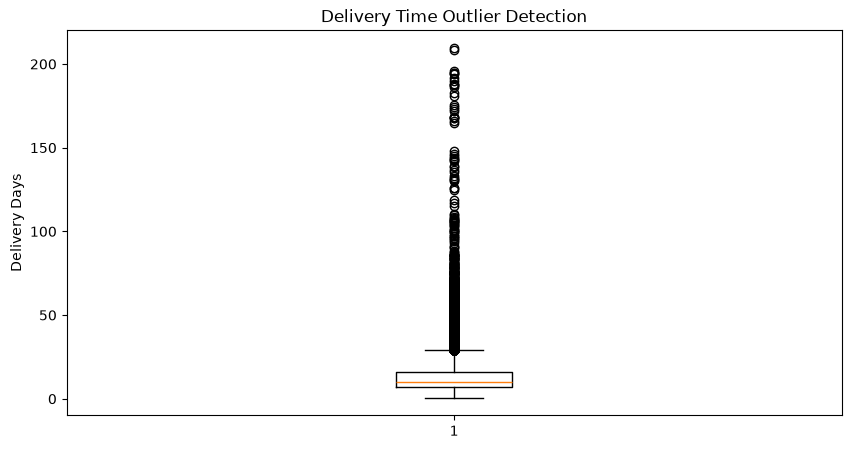

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.boxplot(valid_delivered_orders["delivery_days"])

plt.title("Delivery Time Outlier Detection")
plt.ylabel("Delivery Days")

plt.show()

In [103]:
# Identify delivery-time outliers

Q1 = valid_delivered_orders["delivery_days"].quantile(0.25)
Q3 = valid_delivered_orders["delivery_days"].quantile(0.75)

IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

delivery_outliers = valid_delivered_orders[
    valid_delivered_orders["delivery_days"] > upper_bound
].copy()

print("Total delivery outliers:", len(delivery_outliers))

print("\nOutlier delivery statistics:")
print(delivery_outliers["delivery_days"].describe())

Total delivery outliers: 4896

Outlier delivery statistics:
count    4896.000000
mean       40.788888
std        16.208739
min        29.153472
25%        32.144618
50%        36.155903
75%        43.737500
max       209.628472
Name: delivery_days, dtype: float64


In [104]:
delivery_outliers.nlargest(
    10, "delivery_days"
)[
    ["order_id", "order_purchase_timestamp",
     "order_delivered_customer_date", "delivery_days"]
]

,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:00,2017-09-19 14:36:00,209.628472
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:00,2018-09-19 23:24:00,208.352083
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:00,2017-09-19 15:12:00,195.634028
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:00,2017-09-19 14:33:00,194.850000
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:00,2017-09-19 14:00:00,194.634028
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:00,2017-09-19 14:38:00,194.050000
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:00,2018-07-13 20:51:00,191.463194
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:00,2017-09-19 17:00:00,189.863194
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:00,2017-09-19 14:38:00,188.134722
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:00,2017-09-19 17:14:00,187.743750


In [105]:

# Check delivery outliers by order status

print("Outlier count:", len(delivery_outliers))

# Calculate percentage of outliers
outlier_percentage = (
    len(delivery_outliers) / len(valid_delivered_orders)
) * 100

print("Outlier percentage:", round(outlier_percentage, 2), "%")

# Delivery time distribution among outliers
print("\nOutlier delivery time distribution:")
print(delivery_outliers["delivery_days"].describe())

# Check how many orders took more than 60 days
print(
    "\nOrders taking more than 60 days:",
    (delivery_outliers["delivery_days"] > 60).sum()
)


Outlier count: 4896
Outlier percentage: 5.08 %

Outlier delivery time distribution:
count    4896.000000
mean       40.788888
std        16.208739
min        29.153472
25%        32.144618
50%        36.155903
75%        43.737500
max       209.628472
Name: delivery_days, dtype: float64

Orders taking more than 60 days: 306


In [106]:

# Create delivery outlier flag

valid_delivered_orders["is_delivery_outlier"] = (
    valid_delivered_orders["delivery_days"] > upper_bound
)

# Check results
print("Outlier distribution:")
print(
    valid_delivered_orders["is_delivery_outlier"]
    .value_counts()
)

print("\nOutlier percentages:")
print(
    valid_delivered_orders["is_delivery_outlier"]
    .value_counts(normalize=True) * 100
)


Outlier distribution:
is_delivery_outlier
False    91574
True      4896
Name: count, dtype: int64

Outlier percentages:
is_delivery_outlier
False    94.924847
True      5.075153
Name: proportion, dtype: float64


In [107]:

# Create delivery outlier flag

valid_delivered_orders["is_delivery_outlier"] = (
    valid_delivered_orders["delivery_days"] > upper_bound
)

# Check results
print("Outlier distribution:")
print(
    valid_delivered_orders["is_delivery_outlier"]
    .value_counts()
)

print("\nOutlier percentages:")
print(
    valid_delivered_orders["is_delivery_outlier"]
    .value_counts(normalize=True) * 100
)


Outlier distribution:
is_delivery_outlier
False    91574
True      4896
Name: count, dtype: int64

Outlier percentages:
is_delivery_outlier
False    94.924847
True      5.075153
Name: proportion, dtype: float64


In [108]:

# Orders taking more than 60 days

extreme_delays = valid_delivered_orders[
    valid_delivered_orders["delivery_days"] > 60
].copy()

print("Extreme delayed orders:", len(extreme_delays))

extreme_delays[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_days"
    ]
].head(10)


Extreme delayed orders: 306


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days
252,f31535f21d145b2345e2bf7f09d62322,2018-02-01 07:47:00,2018-04-23 15:49:00,81.334722
658,cafc9b2f7d35ec42bdb74347cc6e8a70,2018-01-19 00:48:00,2018-04-04 17:12:00,75.683333
1536,b5195225c11fc325d686d24fe14eedbb,2018-03-02 10:35:00,2018-05-07 15:59:00,66.225000
1563,56af0400ccac703cca01cd9846d29c58,2018-02-20 17:37:00,2018-05-06 17:08:00,74.979861
1621,a4efaffc506a395c9cea7402b078c1e5,2018-01-17 10:50:00,2018-05-07 19:25:00,110.357639
2619,a69ddc335f989aa05576bc19f8b9a549,2018-01-18 15:46:00,2018-04-18 15:41:00,89.996528
2852,dd501072091c950a1e6bb5ea9182df2a,2018-03-12 13:32:00,2018-05-14 15:18:00,63.073611
3077,8b7fd198ad184563c231653673e75a7f,2017-11-14 10:04:00,2018-02-27 18:05:00,105.334028
3202,4f39a94d6e474819d898d6df7d394996,2017-04-28 16:28:00,2017-09-19 13:54:00,143.893056
3952,039ec885e36627ae6353cfd42a41c5da,2018-02-22 12:45:00,2018-05-03 22:13:00,70.394444


In [109]:
# Classify delivery performance

valid_delivered_orders["delivery_category"] = np.where(
    valid_delivered_orders["delivery_days"] > 60,
    "Extreme Delay",
    np.where(
        valid_delivered_orders["delivery_days"] > 29.15,
        "Delayed",
        "Normal"
    )
)

# Check distribution
print(
    valid_delivered_orders["delivery_category"]
    .value_counts()
)

print("\nPercentage distribution:")
print(
    valid_delivered_orders["delivery_category"]
    .value_counts(normalize=True) * 100
)

delivery_category
Normal           91574
Delayed           4590
Extreme Delay      306
Name: count, dtype: int64

Percentage distribution:
delivery_category
Normal           94.924847
Delayed           4.757956
Extreme Delay     0.317197
Name: proportion, dtype: float64


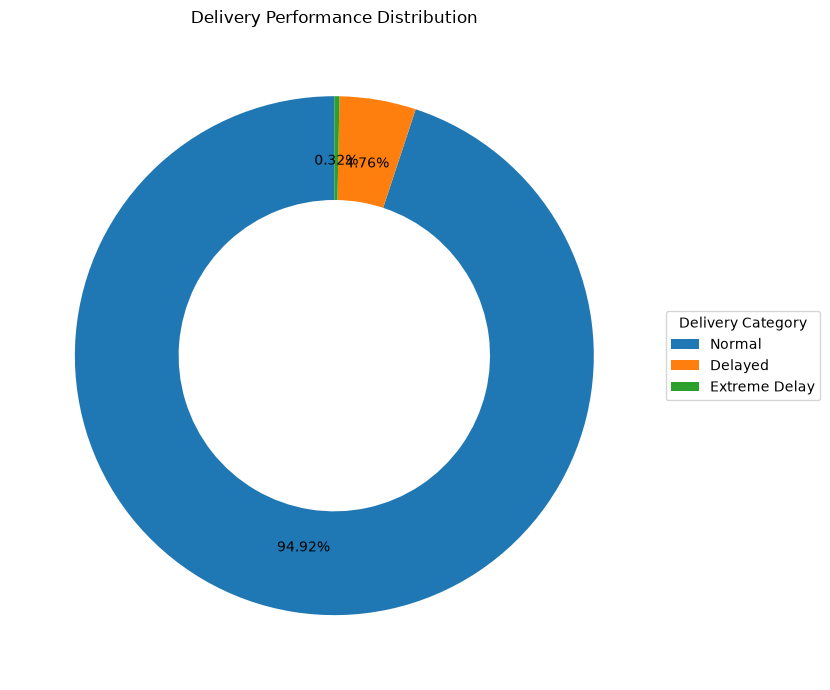

In [110]:
import matplotlib.pyplot as plt

delivery_counts = valid_delivered_orders[
    "delivery_category"
].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    delivery_counts,
    autopct="%1.2f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"width": 0.4},
    textprops={"fontsize": 10}
)

plt.legend(
    delivery_counts.index,
    title="Delivery Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Delivery Performance Distribution")
plt.tight_layout()
plt.show()

In [111]:
### Delivery Performance Analysis

- Total delivered orders analyzed: 96,470
- Normal deliveries: 91,574 (94.92%)
- Delayed deliveries: 4,590 (4.76%)
- Extreme delays: 306 (0.32%)

Business Insight:
Approximately 5.08% of delivered orders experienced
delivery times exceeding the IQR upper boundary.
These orders require further investigation to identify
potential logistics and delivery performance issues.

SyntaxError: invalid syntax (663789074.py, line 3)

In [ ]:
# Calculate actual delivery duration
# and estimated delivery duration

valid_delivered_orders["estimated_delivery_days"] = (
    valid_delivered_orders["order_estimated_delivery_date"] -
    valid_delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery delay
valid_delivered_orders["delivery_delay_days"] = (
    valid_delivered_orders["delivery_days"] -
    valid_delivered_orders["estimated_delivery_days"]
)

# Classify delivery status
valid_delivered_orders["delivery_status"] = np.where(
    valid_delivered_orders["delivery_delay_days"] > 0,
    "Late",
    "On Time"
)

print(valid_delivered_orders["delivery_status"].value_counts())

delivery_status
On Time    88644
Late        7826
Name: count, dtype: int64


In [ ]:
# Filter late orders
late_orders = valid_delivered_orders[
    valid_delivered_orders["delivery_status"] == "Late"
].copy()

# Calculate delay statistics
print("Late Delivery Statistics:")

print(
    late_orders["delivery_delay_days"].describe()
)

Late Delivery Statistics:
count    7826.000000
mean        9.551386
std        13.952540
min         0.002083
25%         1.866667
50%         5.806250
75%        11.820660
max       188.975000
Name: delivery_delay_days, dtype: float64


In [ ]:
# Top 10 most delayed orders

late_orders.nlargest(
    10, "delivery_delay_days"
)[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
        "delivery_delay_days"
    ]
]

,order_id,order_purchase_timestamp,order_estimated_delivery_date,order_delivered_customer_date,delivery_delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:00,2018-03-15,2018-09-19 23:24:00,188.975000
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:00,2017-03-22,2017-09-19 14:36:00,181.608333
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:00,2018-01-19,2018-07-13 20:51:00,175.868750
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:00,2017-04-05,2017-09-19 17:00:00,167.708333
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:00,2017-04-06,2017-09-19 14:00:00,166.583333
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:00,2017-04-07,2017-09-19 15:12:00,165.633333
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:00,2017-04-10,2017-09-19 17:14:00,162.718056
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:00,2017-06-26,2017-12-04 18:36:00,161.775000
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:00,2017-04-11,2017-09-19 14:38:00,161.609722
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:00,2017-04-13,2017-09-19 14:38:00,159.609722


In [ ]:
# Check duplicate records in each dataset

for name, df in datasets.items():

    print(f"\nDataset: {name}")
    print("Duplicate rows:", df.duplicated().sum())


Dataset: olist_customers_dataset
Duplicate rows: 0

Dataset: olist_geolocation_dataset
Duplicate rows: 261831

Dataset: olist_orders_dataset
Duplicate rows: 0

Dataset: olist_order_items_dataset
Duplicate rows: 0

Dataset: olist_order_payments_dataset
Duplicate rows: 0

Dataset: olist_order_reviews_dataset
Duplicate rows: 0

Dataset: olist_products_dataset
Duplicate rows: 0

Dataset: olist_sellers_dataset
Duplicate rows: 0

Dataset: product_category_name_translation
Duplicate rows: 0


In [ ]:
# Check missing values in all datasets

for name, df in datasets.items():

    print(f"\nDataset: {name}")

    missing = df.isnull().sum()

    print(missing[missing > 0])


Dataset: olist_customers_dataset
Series([], dtype: int64)

Dataset: olist_geolocation_dataset
Series([], dtype: int64)

Dataset: olist_orders_dataset
order_purchase_timestamp         59810
order_approved_at                59793
order_delivered_carrier_date     62109
order_delivered_customer_date    63087
dtype: int64

Dataset: olist_order_items_dataset
Series([], dtype: int64)

Dataset: olist_order_payments_dataset
Series([], dtype: int64)

Dataset: olist_order_reviews_dataset
review_comment_title      87656
review_comment_message    58247
dtype: int64

Dataset: olist_products_dataset
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Dataset: olist_sellers_dataset
Series([], dtype: int64)

Dataset: product_category_name_translation
Series([], dtype: int

In [ ]:
# Final data type inspection

for name, df in datasets.items():

    print(f"\nDataset: {name}")
    print(df.dtypes)


Dataset: olist_customers_dataset
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Dataset: olist_geolocation_dataset
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Dataset: olist_orders_dataset
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Dataset: olist_order_items_dataset
order_id                   str
order_item_id            int64
product_id

In [ ]:
# Convert remaining date columns

date_columns = {
    "items": ["shipping_limit_date"],
    "reviews": [
        "review_creation_date",
        "review_answer_timestamp"
    ]
}

datasets = {
    "items": items,
    "reviews": reviews
}

for dataset_name, columns in date_columns.items():

    for column in columns:
        datasets[dataset_name][column] = pd.to_datetime(
            datasets[dataset_name][column],
            errors="coerce"
        )

    print(f"\n{dataset_name}")
    print(datasets[dataset_name][columns].dtypes)


items
shipping_limit_date    datetime64[us]
dtype: object


C:\Users\acer\AppData\Local\Temp\ipykernel_5400\4215358954.py:19: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  datasets[dataset_name][column] = pd.to_datetime(
C:\Users\acer\AppData\Local\Temp\ipykernel_5400\4215358954.py:19: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  datasets[dataset_name][column] = pd.to_datetime(



reviews
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [ ]:
# Correct date conversion

items["shipping_limit_date"] = pd.to_datetime(
    items["shipping_limit_date"],
    dayfirst=True,
    errors="coerce"
)

reviews["review_creation_date"] = pd.to_datetime(
    reviews["review_creation_date"],
    dayfirst=True,
    errors="coerce"
)

reviews["review_answer_timestamp"] = pd.to_datetime(
    reviews["review_answer_timestamp"],
    dayfirst=True,
    errors="coerce"
)

# Verify data types

print("Order Items:")
print(items["shipping_limit_date"].dtype)

print("\nReviews:")
print(reviews[
    ["review_creation_date", "review_answer_timestamp"]
].dtypes)

Order Items:
datetime64[us]

Reviews:
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [ ]:
print("Order Items:")
print(items["shipping_limit_date"].isnull().sum())

print("\nReviews:")
print(reviews[
    ["review_creation_date", "review_answer_timestamp"]
].isnull().sum())

Order Items:
0

Reviews:
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [ ]:
print(reviews[
    ["review_creation_date", "review_answer_timestamp"]
].isnull().sum())

review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [ ]:
# Check duplicate rows

print("Order Items duplicates:", items.duplicated().sum())

print("Reviews duplicates:", reviews.duplicated().sum())

# Check duplicate primary identifiers

print("\nDuplicate order item records:")
print(items.duplicated(
    subset=["order_id", "order_item_id"]
).sum())

print("\nDuplicate review IDs:")
print(reviews["review_id"].duplicated().sum())

Order Items duplicates: 0
Reviews duplicates: 0

Duplicate order item records:
0

Duplicate review IDs:
814


In [ ]:
# Find duplicate review IDs

duplicate_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Total records with duplicate review IDs:",
      len(duplicate_reviews))

duplicate_reviews.head(20)

Total records with duplicate review IDs: 1603


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00


In [ ]:
duplicate_review_summary = (
    duplicate_reviews.groupby("review_id")
    .agg(
        total_records=("order_id", "count"),
        unique_orders=("order_id", "nunique")
    )
)

print(duplicate_review_summary.head(20))

print("\nDuplicate IDs linked to multiple orders:",
      (duplicate_review_summary["unique_orders"] > 1).sum())

                                  total_records  unique_orders
review_id                                                     
00130cbe1f9d422698c812ed8ded1919              2              2
0115633a9c298b6a98bcbe4eee75345f              2              2
0174caf0ee5964646040cd94e15ac95e              2              2
017808d29fd1f942d97e50184dfb4c13              2              2
0254bd905dc677a6078990aad3331a36              2              2
0288d42bef3dfe36930740c9588a570f              2              2
02aa7f5f75e964e3c7efa59a1f515281              2              2
034528cb00b6bc981847acafbdf2ae0b              2              2
03a6a25db577d0689440933055111897              2              2
0467560f511c516ddaa54a60edb0c291              2              2
047fd109ced39e02296f6aeb74f6a6f1              2              2
0498e9722f8757426c3c3ee0b91e666d              2              2
0501aab2f381486c36bf0f071442c0c2              2              2
0546d398a833d4c33dec480bedeecfbd              2        

In [ ]:
duplicate_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

duplicate_reviews[
    [
        "review_id",
        "order_id",
        "review_score",
        "review_comment_title",
        "review_comment_message",
        "review_creation_date",
        "review_answer_timestamp"
    ]
].head(20)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00


In [ ]:
duplicate_review_details = (
    duplicate_reviews.groupby("review_id")
    .agg(
        total_records=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
        unique_comments=("review_comment_message", "nunique")
    )
)

duplicate_review_details.head(20)

,total_records,unique_orders,unique_scores,unique_comments
review_id,,,,
00130cbe1f9d422698c812ed8ded1919,2,2,1,1
0115633a9c298b6a98bcbe4eee75345f,2,2,1,0
0174caf0ee5964646040cd94e15ac95e,2,2,1,1
017808d29fd1f942d97e50184dfb4c13,2,2,1,0
0254bd905dc677a6078990aad3331a36,2,2,1,1
0288d42bef3dfe36930740c9588a570f,2,2,1,0
02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0
034528cb00b6bc981847acafbdf2ae0b,2,2,1,0
03a6a25db577d0689440933055111897,2,2,1,1


In [ ]:
print("Total duplicate review IDs:",
      duplicate_review_details.shape[0])

print("\nNumber of IDs linked to multiple orders:",
      (duplicate_review_details["unique_orders"] > 1).sum())

print("\nDuplicate IDs with different review scores:",
      (duplicate_review_details["unique_scores"] > 1).sum())

print("\nDuplicate IDs with different comments:",
      (duplicate_review_details["unique_comments"] > 1).sum())

print("\nNumber of records involved:",
      len(duplicate_reviews))

Total duplicate review IDs: 789

Number of IDs linked to multiple orders: 789

Duplicate IDs with different review scores: 0

Duplicate IDs with different comments: 0

Number of records involved: 1603


In [ ]:
print("Duplicate order IDs in reviews:",
      reviews["order_id"].duplicated().sum())

print("Unique order IDs in reviews:",
      reviews["order_id"].nunique())

print("Total review records:",
      len(reviews))

Duplicate order IDs in reviews: 551
Unique order IDs in reviews: 98673
Total review records: 99224


In [ ]:
reviews_per_order = (
    reviews.groupby("order_id")
    .size()
    .reset_index(name="review_count")
)

print("Orders with multiple review records:",
      (reviews_per_order["review_count"] > 1).sum())

print("\nDistribution of review records per order:")
print(reviews_per_order["review_count"].value_counts().sort_index())

Orders with multiple review records: 547

Distribution of review records per order:
review_count
1    98126
2      543
3        4
Name: count, dtype: int64


In [ ]:
multiple_reviews = reviews_per_order[
    reviews_per_order["review_count"] > 1
].sort_values("review_count", ascending=False)

multiple_reviews.head(10)

,order_id,review_count
1455,03c939fd7fd3b38f8485a0f95798f1f6,3
54489,8e17072ec97ce29f0e1f111e598b0c85,3
77319,c88b1d1b157a9999ce368f218a407141,3
86232,df56136b8031ecd28e200bb18e6ddb2e,3
835,02355020fd0a40a0d56df9f6ff060413,2
985,029863af4b968de1e5d6a82782e662f5,2
1092,02e0b68852217f5715fb9cc885829454,2
1103,02e723e8edb4a123d414f56cc9c4665e,2
1272,03515a836bb855b03f7df9dee520a8fc,2
1510,03eba6d9fef8f5b3e811d4b5a7cca9cd,2


In [ ]:
multiple_order_ids = multiple_reviews["order_id"]

multiple_review_records = reviews[
    reviews["order_id"].isin(multiple_order_ids)
].sort_values(["order_id", "review_creation_date"])

multiple_review_records[
    [
        "order_id",
        "review_id",
        "review_score",
        "review_comment_title",
        "review_comment_message",
        "review_creation_date"
    ]
].head(20)

,order_id,review_id,review_score,review_comment_title,review_comment_message,review_creation_date
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,NaN,NaN,2017-08-29
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,NaN,NaN,2018-02-22
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,NaN,NaN,2018-03-04
854,0176a6846bcb3b0d3aa3116a9a768597,830636803620cdf8b6ffaf1b2f6e92b2,5,NaN,NaN,2017-12-30
83224,0176a6846bcb3b0d3aa3116a9a768597,d8e8c42271c8fb67b9dad95d98c8ff80,5,NaN,NaN,2017-12-30
89888,02355020fd0a40a0d56df9f6ff060413,0c8e7347f1cdd2aede37371543e3d163,3,NaN,UM DOS PRODUTOS (ENTREGA02) COMPRADOS NESTE PE...,2018-03-21
17582,02355020fd0a40a0d56df9f6ff060413,017f0e1ea6386de662cbeba299c59ad1,1,NaN,ja reclamei varias vezes e ate hoje não sei on...,2018-03-29
37911,029863af4b968de1e5d6a82782e662f5,04d945e95c788a3aa1ffbee42105637b,5,NaN,NaN,2017-07-14
55137,029863af4b968de1e5d6a82782e662f5,61fe4e7d1ae801bbe169eb67b86c6eda,4,NaN,NaN,2017-07-19


In [ ]:
print("Review score distribution:")
print(reviews["review_score"].value_counts().sort_index())

print("\nMissing values in reviews:")
print(reviews.isnull().sum())

print("\nReview dataset shape:")
print(reviews.shape)

Review score distribution:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Missing values in reviews:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Review dataset shape:
(99224, 7)


In [ ]:
reviews_cleaned = reviews.copy()

print("Original reviews shape:", reviews.shape)
print("Cleaned reviews shape:", reviews_cleaned.shape)

print("\nMissing comments retained:")
print(reviews_cleaned[
    ["review_comment_title", "review_comment_message"]
].isnull().sum())

Original reviews shape: (99224, 7)
Cleaned reviews shape: (99224, 7)

Missing comments retained:
review_comment_title      87656
review_comment_message    58247
dtype: int64


In [ ]:
print("Order Items Dataset Shape:", items.shape)

print("\nColumn Names:")
print(items.columns.tolist())

print("\nData Types:")
print(items.dtypes)

print("\nMissing Values:")
print(items.isnull().sum())

print("\nFirst 5 Records:")
display(items.head())

Order Items Dataset Shape: (112650, 7)

Column Names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Data Types:
order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

First 5 Records:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
print("Exact duplicate rows:",
      items.duplicated().sum())

print("\nDuplicate order-item combinations:",
      items.duplicated(
          subset=["order_id", "order_item_id"]
      ).sum())

print("\nDuplicate order IDs:",
      items["order_id"].duplicated().sum())

print("\nUnique orders:",
      items["order_id"].nunique())

Exact duplicate rows: 0

Duplicate order-item combinations: 0

Duplicate order IDs: 13984

Unique orders: 98666


In [ ]:
print("Negative product prices:",
      (items["price"] < 0).sum())

print("Zero product prices:",
      (items["price"] == 0).sum())

print("Negative freight values:",
      (items["freight_value"] < 0).sum())

print("Zero freight values:",
      (items["freight_value"] == 0).sum())

print("\nPrice statistics:")
print(items["price"].describe())

print("\nFreight value statistics:")
print(items["freight_value"].describe())

Negative product prices: 0
Zero product prices: 0
Negative freight values: 0
Zero freight values: 383

Price statistics:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Freight value statistics:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


In [ ]:
zero_freight = items[items["freight_value"] == 0]

print("Zero freight records:", len(zero_freight))

print("\nUnique orders with zero freight:",
      zero_freight["order_id"].nunique())

print("\nUnique products with zero freight:",
      zero_freight["product_id"].nunique())

display(zero_freight.head(10))

Zero freight records: 383

Unique orders with zero freight: 339

Unique products with zero freight: 10


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
114,00404fa7a687c8c44ca69d42695aae73,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-15 04:31:26,99.9,0.0
258,00a870c6c06346e85335524935c600c0,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-14 00:14:29,69.9,0.0
483,011c899816ea29773525bd3322dbb6aa,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-07 05:30:45,99.9,0.0
508,012b3f6ab7776a8ab3443a4ad7bef2e6,1,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
509,012b3f6ab7776a8ab3443a4ad7bef2e6,2,422879e10f46682990de24d770e7f83d,1f50f920176fa81dab994f9023523100,2018-05-09 21:30:50,53.9,0.0
1784,04105b54650921ca3246f52e6f175f46,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-04-27 09:31:35,69.9,0.0
2232,0517a3e68dac3308995edca2144db36e,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-03 19:11:40,99.9,0.0
2714,061ba2e2d7544790b6ed6b5b4dd9278c,1,53b36df67ebb7c41585e8d54d6772e08,7d13fca15225358621be4086e1eb0964,2018-05-09 23:10:46,110.0,0.0
3224,07441f525824bc6b31d4dc19c5d49fc9,1,53b36df67ebb7c41585e8d54d6772e08,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-26 13:31:30,106.9,0.0
3378,079f16689c29acb6cab92978e6af2137,1,aca2eb7d00ea1a7b8ebd4e68314663af,955fee9216a65b617aa5c0531780ce60,2018-05-11 18:15:13,69.9,0.0


In [ ]:
print("Negative product prices:",
      (items["price"] < 0).sum())

print("Zero product prices:",
      (items["price"] == 0).sum())

print("Negative freight values:",
      (items["freight_value"] < 0).sum())

print("Zero freight values:",
      (items["freight_value"] == 0).sum())

print("\nPrice statistics:")
print(items["price"].describe())

print("\nFreight value statistics:")
print(items["freight_value"].describe())

Negative product prices: 0
Zero product prices: 0
Negative freight values: 0
Zero freight values: 383

Price statistics:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Freight value statistics:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


In [ ]:
print("Earliest shipping limit date:",
      items["shipping_limit_date"].min())

print("Latest shipping limit date:",
      items["shipping_limit_date"].max())

print("\nShipping dates before 2016:",
      (items["shipping_limit_date"] < "2016-01-01").sum())

print("Shipping dates after 2019:",
      (items["shipping_limit_date"] >= "2019-01-01").sum())

print("\nShipping date duplicates:",
      items["shipping_limit_date"].duplicated().sum())

Earliest shipping limit date: 2016-09-19 00:15:34
Latest shipping limit date: 2020-04-09 22:35:08

Shipping dates before 2016: 0
Shipping dates after 2019: 4

Shipping date duplicates: 19332


In [ ]:
unusual_shipping_dates = items[
    items["shipping_limit_date"] >= "2019-01-01"
]

display(unusual_shipping_dates)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
8643,13bdf405f961a6deec817d817f5c6624,1,96ea060e41bdecc64e2de00b97068975,7a241947449cc45dbfda4f9d0798d9d0,2020-02-05 03:30:51,69.99,14.66
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,1,282b126b2354516c5f400154398f616d,7a241947449cc45dbfda4f9d0798d9d0,2020-02-03 20:23:22,75.99,14.70
85729,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44
85730,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44


In [ ]:
unusual_shipping_dates = items[
    items["shipping_limit_date"] >= "2019-01-01"
]

display(unusual_shipping_dates)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
8643,13bdf405f961a6deec817d817f5c6624,1,96ea060e41bdecc64e2de00b97068975,7a241947449cc45dbfda4f9d0798d9d0,2020-02-05 03:30:51,69.99,14.66
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,1,282b126b2354516c5f400154398f616d,7a241947449cc45dbfda4f9d0798d9d0,2020-02-03 20:23:22,75.99,14.70
85729,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44
85730,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44


In [ ]:
unusual_shipping_check = unusual_shipping_dates.merge(
    orders[
        ["order_id", "order_purchase_timestamp", "order_status"]
    ],
    on="order_id",
    how="left"
)

display(unusual_shipping_check)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,order_status
0,13bdf405f961a6deec817d817f5c6624,1,96ea060e41bdecc64e2de00b97068975,7a241947449cc45dbfda4f9d0798d9d0,2020-02-05 03:30:51,69.99,14.66,2017-03-16 02:30:00,canceled
1,9c94a4ea2f7876660fa6f1b59b69c8e6,1,282b126b2354516c5f400154398f616d,7a241947449cc45dbfda4f9d0798d9d0,2020-02-03 20:23:22,75.99,14.70,2017-03-14 19:23:00,shipped
2,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,2017-05-23 22:28:00,delivered
3,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,2017-05-23 22:28:00,delivered


In [ ]:
display(
    unusual_shipping_check[
        [
            "order_id",
            "order_item_id",
            "shipping_limit_date",
            "order_purchase_timestamp",
            "order_status"
        ]
    ].to_string(index=False)
)

'                        order_id  order_item_id shipping_limit_date order_purchase_timestamp order_status\n13bdf405f961a6deec817d817f5c6624              1 2020-02-05 03:30:51      2017-03-16 02:30:00     canceled\n9c94a4ea2f7876660fa6f1b59b69c8e6              1 2020-02-03 20:23:22      2017-03-14 19:23:00      shipped\nc2bb89b5c1dd978d507284be78a04cb2              1 2020-04-09 22:35:08      2017-05-23 22:28:00    delivered\nc2bb89b5c1dd978d507284be78a04cb2              2 2020-04-09 22:35:08      2017-05-23 22:28:00    delivered'

In [ ]:
unusual_shipping_check["days_until_shipping_limit"] = (
    unusual_shipping_check["shipping_limit_date"]
    - unusual_shipping_check["order_purchase_timestamp"]
).dt.total_seconds() / 86400

display(
    unusual_shipping_check[
        [
            "order_id",
            "order_purchase_timestamp",
            "shipping_limit_date",
            "days_until_shipping_limit",
            "order_status"
        ]
    ]
)

,order_id,order_purchase_timestamp,shipping_limit_date,days_until_shipping_limit,order_status
0,13bdf405f961a6deec817d817f5c6624,2017-03-16 02:30:00,2020-02-05 03:30:51,1056.042257,canceled
1,9c94a4ea2f7876660fa6f1b59b69c8e6,2017-03-14 19:23:00,2020-02-03 20:23:22,1056.041921,shipped
2,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:00,2020-04-09 22:35:08,1052.004954,delivered
3,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:00,2020-04-09 22:35:08,1052.004954,delivered


In [ ]:
items_cleaned = items.copy()

items_cleaned["shipping_date_anomaly"] = (
    items_cleaned["shipping_limit_date"] >= "2019-01-01"
)

print("Original shape:", items.shape)
print("Cleaned shape:", items_cleaned.shape)

print(
    "Flagged shipping-date anomalies:",
    items_cleaned["shipping_date_anomaly"].sum()
)

print(
    "Records retained:",
    len(items_cleaned)
)

Original shape: (112650, 7)
Cleaned shape: (112650, 8)
Flagged shipping-date anomalies: 4
Records retained: 112650


In [ ]:
Q1 = items_cleaned["price"].quantile(0.25)
Q3 = items_cleaned["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

price_outliers = items_cleaned[
    (items_cleaned["price"] < lower_bound) |
    (items_cleaned["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nPrice outliers:", len(price_outliers))
print("Percentage of outliers:",
      round(len(price_outliers) / len(items_cleaned) * 100, 2), "%")

print("\nOutlier price statistics:")
print(price_outliers["price"].describe())

Q1: 39.9
Q3: 134.9
IQR: 95.0
Lower Bound: -102.6
Upper Bound: 277.4

Price outliers: 8427
Percentage of outliers: 7.48 %

Outlier price statistics:
count    8427.000000
mean      574.291188
std       431.196659
min       277.450000
25%       329.000000
50%       409.990000
75%       649.000000
max      6735.000000
Name: price, dtype: float64


In [ ]:
display(
    price_outliers[
        [
            "order_id",
            "product_id",
            "price",
            "freight_value"
        ]
    ]
    .sort_values("price", ascending=False)
    .head(15)
)

,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01


In [ ]:
Q1_freight = items_cleaned["freight_value"].quantile(0.25)
Q3_freight = items_cleaned["freight_value"].quantile(0.75)

IQR_freight = Q3_freight - Q1_freight

lower_freight = Q1_freight - 1.5 * IQR_freight
upper_freight = Q3_freight + 1.5 * IQR_freight

freight_outliers = items_cleaned[
    (items_cleaned["freight_value"] < lower_freight) |
    (items_cleaned["freight_value"] > upper_freight)
]

print("Freight Q1:", Q1_freight)
print("Freight Q3:", Q3_freight)
print("Freight IQR:", IQR_freight)
print("Lower bound:", lower_freight)
print("Upper bound:", upper_freight)

print("\nFreight outliers:", len(freight_outliers))
print("Outlier percentage:",
      round(len(freight_outliers) / len(items_cleaned) * 100, 2), "%")

print("\nFreight outlier statistics:")
print(freight_outliers["freight_value"].describe())


Freight Q1: 13.08
Freight Q3: 21.15
Freight IQR: 8.069999999999999
Lower bound: 0.9750000000000032
Upper bound: 33.254999999999995

Freight outliers: 12134
Outlier percentage: 10.77 %

Freight outlier statistics:
count    12134.000000
mean        52.004304
std         30.384303
min          0.000000
25%         37.100000
50%         44.040000
75%         58.900000
max        409.680000
Name: freight_value, dtype: float64


In [ ]:
display(
    freight_outliers[
        [
            "order_id",
            "order_item_id",
            "product_id",
            "price",
            "freight_value"
        ]
    ]
    .sort_values("freight_value", ascending=False)
    .head(15)
)

,order_id,order_item_id,product_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,1,ec31d2a17b299511e7c8627be9337b9b,979.00,409.68
28044,3fde74c28a3d5d618c00f26d51baafa0,1,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
3303,076d1555fb53a89b0ef4d529e527a0f6,1,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
69797,9f49bd16053df810384e793386312674,1,256a9c364b75753b97bee410c9491ad8,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,1,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,1,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,1,46e24ce614899e36617e37ea1e4aa6ff,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,1,363a9f5b97bf194da23858be722a7aa5,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,1,7e53e051875b2a0c9f22acd8a9a29a20,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,1,363a9f5b97bf194da23858be722a7aa5,1045.00,314.40


In [ ]:
items_cleaned["price_outlier"] = (
    items_cleaned["price"] > upper_bound
)

items_cleaned["freight_outlier"] = (
    (items_cleaned["freight_value"] < lower_freight) |
    (items_cleaned["freight_value"] > upper_freight)
)

print("Final order-items shape:", items_cleaned.shape)

print("\nPrice outliers flagged:",
      items_cleaned["price_outlier"].sum())

print("Freight outliers flagged:",
      items_cleaned["freight_outlier"].sum())

print("\nMissing values:")
print(items_cleaned.isnull().sum())

Final order-items shape: (112650, 10)

Price outliers flagged: 8427
Freight outliers flagged: 12134

Missing values:
order_id                 0
order_item_id            0
product_id               0
seller_id                0
shipping_limit_date      0
price                    0
freight_value            0
shipping_date_anomaly    0
price_outlier            0
freight_outlier          0
dtype: int64


In [ ]:
items_cleaned.to_csv(
    "olist_order_items_cleaned.csv",
    index=False
)

print("Cleaned order-items dataset exported successfully!")

Cleaned order-items dataset exported successfully!


In [ ]:
print("Products Dataset Shape:", products.shape)

print("\nColumn Names:")
print(products.columns.tolist())

print("\nData Types:")
print(products.dtypes)

print("\nMissing Values:")
print(products.isnull().sum())

print("\nExact Duplicate Rows:")
print(products.duplicated().sum())

display(products.head())

Products Dataset Shape: (32951, 9)

Column Names:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Data Types:
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

Missing Values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Exact Duplicate Rows:
0


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [ ]:
products_cleaned = products.copy()

# Check missing-value patterns
missing_products = products_cleaned[
    products_cleaned.isnull().any(axis=1)
]

print("Records with missing values:", len(missing_products))

print("\nMissing values by column:")
print(products_cleaned.isnull().sum())

print("\nMissing-value combinations:")
print(
    missing_products.isnull()
    .value_counts()
)

print("\nDuplicate product IDs:")
print(products_cleaned["product_id"].duplicated().sum())

display(missing_products.head(10))

Records with missing values: 611

Missing values by column:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Missing-value combinations:
product_id  product_category_name  product_name_lenght  product_description_lenght  product_photos_qty  product_weight_g  product_length_cm  product_height_cm  product_width_cm
False       True                   True                 True                        True                False             False              False              False               609
            False                  False                False                       False               True              True               True               True                  1
            True                   True        

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
244,e10758160da97891c2fdcbc35f0f031d,NaN,NaN,NaN,NaN,2200.0,16.0,2.0,11.0
294,39e3b9b12cd0bf8ee681bbc1c130feb5,NaN,NaN,NaN,NaN,300.0,16.0,7.0,11.0
299,794de06c32a626a5692ff50e4985d36f,NaN,NaN,NaN,NaN,300.0,18.0,8.0,14.0
347,7af3e2da474486a3519b0cba9dea8ad9,NaN,NaN,NaN,NaN,200.0,22.0,14.0,14.0
428,629beb8e7317703dcc5f35b5463fd20e,NaN,NaN,NaN,NaN,1400.0,25.0,25.0,25.0


In [ ]:
dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

missing_dimensions = products_cleaned[
    products_cleaned[dimension_columns].isnull().any(axis=1)
]

print("Products with missing dimensions:", len(missing_dimensions))

display(missing_dimensions)

Products with missing dimensions: 2


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
measurement_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

for col in measurement_columns:
    print(f"\n{col}")
    print("Zero values:", (products_cleaned[col] == 0).sum())
    print("Negative values:", (products_cleaned[col] < 0).sum())
    print("Minimum:", products_cleaned[col].min())
    print("Maximum:", products_cleaned[col].max())


product_weight_g
Zero values: 4
Negative values: 0
Minimum: 0.0
Maximum: 40425.0

product_length_cm
Zero values: 0
Negative values: 0
Minimum: 7.0
Maximum: 105.0

product_height_cm
Zero values: 0
Negative values: 0
Minimum: 2.0
Maximum: 105.0

product_width_cm
Zero values: 0
Negative values: 0
Minimum: 6.0
Maximum: 118.0


In [ ]:
zero_weight_products = products_cleaned[
    products_cleaned["product_weight_g"] == 0
]

print("Products with zero weight:", len(zero_weight_products))

display(zero_weight_products)

Products with zero weight: 4


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0


In [ ]:
heavy_products = products_cleaned[
    products_cleaned["product_weight_g"] > 20000
].sort_values(
    "product_weight_g",
    ascending=False
)

print("Products weighing over 20 kg:", len(heavy_products))

display(heavy_products)

Products weighing over 20 kg: 485


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
25166,26644690fde745fc4654719c3904e1db,cama_mesa_banho,59.0,534.0,1.0,40425.0,13.0,65.0,28.0
32532,90c1b4e040d1d1c45897ec2dad4a809d,moveis_sala,57.0,837.0,2.0,30000.0,63.0,63.0,74.0
31098,0db01fdc451cdba4ee06ff86de2885a7,moveis_sala,42.0,695.0,1.0,30000.0,47.0,42.0,74.0
32491,2b752ed328ea866e4721ca4e236a416c,moveis_cozinha_area_de_servico_jantar_e_jardim,47.0,2201.0,4.0,30000.0,16.0,2.0,11.0
30989,ffa4ff381e25872b5bf85353ff7ab0c9,esporte_lazer,25.0,422.0,1.0,30000.0,80.0,51.0,44.0
...,...,...,...,...,...,...,...,...,...
21581,0d1b16618de7d0c6143e934ea38619e0,automotivo,51.0,652.0,1.0,20050.0,80.0,40.0,40.0
4503,34f7bddc98259b62a001644be7928e43,eletrodomesticos_2,55.0,943.0,1.0,20050.0,44.0,45.0,62.0
4493,8516ee98a593fbd30f6ab57f3d3477bd,moveis_escritorio,38.0,506.0,2.0,20050.0,101.0,10.0,62.0
2896,fdbfd4cec6db6e89f22d9aa2c4839eed,casa_construcao,60.0,362.0,2.0,20050.0,55.0,25.0,55.0


In [ ]:

zero_weight_check = products_cleaned[
    products_cleaned["product_weight_g"] == 0
][
    [
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ]
]

display(zero_weight_check)


,product_id,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,0.0,30.0,25.0,30.0
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,0.0,30.0,25.0,30.0
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,0.0,30.0,25.0,30.0
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,0.0,30.0,25.0,30.0


In [ ]:

products_cleaned["zero_weight_flag"] = (
    products_cleaned["product_weight_g"] == 0
)

print("Zero-weight products flagged:",
      products_cleaned["zero_weight_flag"].sum())

print("Total product records:",
      len(products_cleaned))

display(
    products_cleaned[
        products_cleaned["zero_weight_flag"]
    ]
)


Zero-weight products flagged: 4
Total product records: 32951


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,zero_weight_flag
9769,81781c0fed9fe1ad6e8c81fca1e1cb08,cama_mesa_banho,51.0,529.0,1.0,0.0,30.0,25.0,30.0,True
13683,8038040ee2a71048d4bdbbdc985b69ab,cama_mesa_banho,48.0,528.0,1.0,0.0,30.0,25.0,30.0,True
14997,36ba42dd187055e1fbe943b2d11430ca,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0,True
32079,e673e90efa65a5409ff4196c038bb5af,cama_mesa_banho,53.0,528.0,1.0,0.0,30.0,25.0,30.0,True


In [ ]:

missing_catalogue = products_cleaned[
    products_cleaned["product_category_name"].isna()
]

print("Products with missing category:",
      len(missing_catalogue))

print("Missing category and name length:",
      missing_catalogue["product_name_lenght"].isna().sum())

print("Missing category and description length:",
      missing_catalogue["product_description_lenght"].isna().sum())

print("Missing category and photo quantity:",
      missing_catalogue["product_photos_qty"].isna().sum())

print("Products also appearing in order items:",
      missing_catalogue["product_id"].isin(
          items["product_id"]
      ).sum())


Products with missing category: 610
Missing category and name length: 610
Missing category and description length: 610
Missing category and photo quantity: 610
Products also appearing in order items: 610


In [ ]:

catalogue_columns = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

products_cleaned["missing_catalogue_flag"] = (
    products_cleaned[catalogue_columns].isna().all(axis=1)
)

print(
    "Products with missing catalogue information:",
    products_cleaned["missing_catalogue_flag"].sum()
)

print("Total product records:", len(products_cleaned))

print("\nMissing values after flagging:")
print(products_cleaned.isnull().sum())


Products with missing catalogue information: 610
Total product records: 32951

Missing values after flagging:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
zero_weight_flag                0
missing_catalogue_flag          0
dtype: int64


In [ ]:

# Get product IDs with missing physical dimensions
missing_dimension_ids = products_cleaned.loc[
    products_cleaned[
        ["product_weight_g", "product_length_cm",
         "product_height_cm", "product_width_cm"]
    ].isna().any(axis=1),
    "product_id"
]

# Check whether these products appear in order items
dimension_products_in_orders = items[
    items["product_id"].isin(missing_dimension_ids)
]

print("Products with missing dimensions:", len(missing_dimension_ids))
print("Related order-item records:", len(dimension_products_in_orders))

display(dimension_products_in_orders.head(20))


Products with missing dimensions: 2
Related order-item records: 18


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
7098,101157d4fae1c9fb74a00a5dee265c25,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-11 08:02:26,29.0,14.52
9233,1521c6bb7b1028154c8c67cf80fa809f,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-07 10:10:16,29.0,16.05
28715,415cfaaaa8cea49f934470548797fed1,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-07 10:35:19,29.0,14.52
28716,415cfaaaa8cea49f934470548797fed1,2,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-07 10:35:19,29.0,14.52
39299,595316a07cd3dea9db7adfcc7e247ae7,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-08-18 04:26:04,39.0,9.27
48424,6e150190fbe04c642a9cf0b80d83ee16,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-06-30 16:45:14,39.0,16.79
48980,6f497c40431d5fb0cfbd6c943dd29215,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-11 05:55:32,29.0,10.96
58833,85f8ad45e067abd694b627859fa57453,1,09ff539a621711667c43eba6a3bd8466,8b8cfc8305aa441e4239358c9f6f2485,2017-02-03 21:40:02,1934.0,27.00
71134,a2456e7f02197951664897a94c87242d,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-04-06 11:50:09,29.0,24.84
73556,a7a43f469c0d7bdb0a23a82db125aefa,1,5eb564652db742ff8f28759cd8d2652a,4e922959ae960d389249c378d1c939f5,2017-08-28 13:15:11,39.0,15.10


In [ ]:

dimension_columns = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

products_cleaned["missing_dimensions_flag"] = (
    products_cleaned[dimension_columns]
    .isna()
    .any(axis=1)
)

print(
    "Products with missing dimensions:",
    products_cleaned["missing_dimensions_flag"].sum()
)

print(
    "Total product records:",
    len(products_cleaned)
)

display(
    products_cleaned[
        products_cleaned["missing_dimensions_flag"]
    ]
)


Products with missing dimensions: 2
Total product records: 32951


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,zero_weight_flag,missing_catalogue_flag,missing_dimensions_flag
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN,False,False,True
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,True,True


In [ ]:

print("PRODUCT DATA VALIDATION")
print("-" * 40)

print("Original product records:", len(products))
print("Cleaned product records:", len(products_cleaned))

print("\nDuplicate product IDs:",
      products_cleaned["product_id"].duplicated().sum())

print("\nMissing catalogue flag:",
      products_cleaned["missing_catalogue_flag"].sum())

print("Missing dimensions flag:",
      products_cleaned["missing_dimensions_flag"].sum())

print("Zero weight flag:",
      products_cleaned["zero_weight_flag"].sum())

print("\nMissing values in flag columns:")
flag_columns = [
    "zero_weight_flag",
    "missing_catalogue_flag",
    "missing_dimensions_flag"
]

print(products_cleaned[flag_columns].isna().sum())


PRODUCT DATA VALIDATION
----------------------------------------
Original product records: 32951
Cleaned product records: 32951

Duplicate product IDs: 0

Missing catalogue flag: 610
Missing dimensions flag: 2
Zero weight flag: 4

Missing values in flag columns:
zero_weight_flag           0
missing_catalogue_flag     0
missing_dimensions_flag    0
dtype: int64


In [ ]:

# Identify every record belonging to a duplicated review ID
duplicate_reviews = reviews[
    reviews["review_id"].duplicated(keep=False)
].sort_values("review_id")

print("Total records with duplicated review IDs:",
      len(duplicate_reviews))

print("Unique duplicated review IDs:",
      duplicate_reviews["review_id"].nunique())

display(duplicate_reviews.head(20))


Total records with duplicated review IDs: 1603
Unique duplicated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:00
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21,2017-09-26 03:27:00
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07,2018-03-08 03:00:00
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02,2018-03-05 01:43:00
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09,2017-09-13 09:52:00


In [ ]:
# Count how many times each review ID appears
review_id_counts = (
    reviews["review_id"]
    .value_counts()
)

# Summarise duplicate review IDs
print("Total duplicated review IDs:",
      (review_id_counts > 1).sum())

print("\nFrequency of duplicate review IDs:")
print(review_id_counts[review_id_counts > 1].value_counts().sort_index())

Total duplicated review IDs: 789

Frequency of duplicate review IDs:
count
2    764
3     25
Name: count, dtype: int64


In [ ]:
# Group duplicated review IDs and examine their associated orders
duplicate_review_summary = (
    reviews[reviews["review_id"].duplicated(keep=False)]
    .groupby("review_id")
    .agg(
        total_records=("order_id", "count"),
        unique_orders=("order_id", "nunique"),
        unique_scores=("review_score", "nunique"),
        unique_messages=("review_comment_message", "nunique")
    )
)

print("Duplicate review ID summary:")
display(duplicate_review_summary.head(15))

print(
    "\nDuplicate IDs associated with multiple orders:",
    (duplicate_review_summary["unique_orders"] > 1).sum()
)

print(
    "Duplicate IDs with different review scores:",
    (duplicate_review_summary["unique_scores"] > 1).sum()
)

Duplicate review ID summary:


,total_records,unique_orders,unique_scores,unique_messages
review_id,,,,
00130cbe1f9d422698c812ed8ded1919,2,2,1,1
0115633a9c298b6a98bcbe4eee75345f,2,2,1,0
0174caf0ee5964646040cd94e15ac95e,2,2,1,1
017808d29fd1f942d97e50184dfb4c13,2,2,1,0
0254bd905dc677a6078990aad3331a36,2,2,1,1
0288d42bef3dfe36930740c9588a570f,2,2,1,0
02aa7f5f75e964e3c7efa59a1f515281,2,2,1,0
034528cb00b6bc981847acafbdf2ae0b,2,2,1,0
03a6a25db577d0689440933055111897,2,2,1,1



Duplicate IDs associated with multiple orders: 789
Duplicate IDs with different review scores: 0


In [ ]:
# Check whether duplicated review IDs have identical review details
review_detail_columns = [
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp"
]

duplicate_review_details = (
    reviews[reviews["review_id"].duplicated(keep=False)]
    .groupby("review_id")[review_detail_columns]
    .nunique(dropna=False)
)

print("Review IDs with different review details:",
      (duplicate_review_details > 1).any(axis=1).sum())

print("\nDifferences by column:")
display((duplicate_review_details > 1).sum())

Review IDs with different review details: 0

Differences by column:


review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

In [ ]:

# Flag review IDs that appear more than once
reviews_cleaned = reviews.copy()

reviews_cleaned["duplicate_review_id_flag"] = (
    reviews_cleaned["review_id"].duplicated(keep=False)
)

print(
    "Records with duplicated review IDs:",
    reviews_cleaned["duplicate_review_id_flag"].sum()
)

print("Original review records:", len(reviews))
print("Cleaned review records:", len(reviews_cleaned))

display(
    reviews_cleaned[
        reviews_cleaned["duplicate_review_id_flag"]
    ].head(10)
)


Records with duplicated review IDs: 1603
Original review records: 99224
Cleaned review records: 99224


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,duplicate_review_id_flag
200,28642ce6250b94cc72bc85960aec6c62,e239d280236cdd3c40cb2c033f681d1c,5,NaN,NaN,2018-03-25,2018-03-25 21:03:00,True
344,a0a641414ff718ca079b3967ef5c2495,169d7e0fd71d624d306f132acd791cbe,5,NaN,NaN,2018-03-04,2018-03-06 20:12:00,True
346,f4d74b17cd63ee35efa82cd2567de911,f269e83a82f64baa3de97c2ebf3358f6,3,NaN,"A embalagem deixou a desejar, por pouco o prod...",2018-01-12,2018-01-13 18:46:00,True
360,ecbaf1fce7d2c09bfab46f89065afeaf,2451b9756f310d4cff5c7987b393870d,5,NaN,NaN,2017-07-27,2017-07-28 16:57:00,True
393,6b1de94de0f4bd84dfc4136818242faa,92acf87839903a94aeca0e5040d99acb,5,NaN,NaN,2018-02-16,2018-02-19 19:04:00,True
433,957011305e7a4b6c8a266eeeb8e0316d,54b4da510fed5dc3cf3e7a8e50a5f224,4,NaN,NaN,2018-03-10,2018-03-10 23:35:00,True
508,b34f4a786bf00b7c8486141ba482783b,b2501eb5c292d415f52576b3d4b5de74,3,NaN,NaN,2017-05-04,2017-05-22 12:02:00,True
661,d433c252647c51309432ca0b763f969b,448795135b904d057254f5fd0d5a6a4c,1,NaN,NaN,2017-09-03,2017-09-06 16:11:00,True
723,5f35bbde2b32b8617aab15b7a9a0ae24,ba568688e2f462d7c44a3fdc62e6456f,4,NaN,NaN,2017-11-26,2017-11-27 21:00:00,True
764,c5976a5a98e854fb23d7e03c6754ae60,2002ea16e75277eaa0b5d78632048540,5,NaN,NaN,2017-08-08,2017-08-10 11:11:00,True


In [ ]:

# Validate review scores
print("Review score distribution:")
display(reviews_cleaned["review_score"].value_counts().sort_index())

print("\nInvalid review scores:",
      (~reviews_cleaned["review_score"].between(1, 5)).sum())

print("\nMissing values in review dataset:")
display(reviews_cleaned.isnull().sum())

print("\nDuplicate review flag counts:")
display(reviews_cleaned["duplicate_review_id_flag"].value_counts())


Review score distribution:


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


Invalid review scores: 0

Missing values in review dataset:


review_id                       0
order_id                        0
review_score                    0
review_comment_title        87656
review_comment_message      58247
review_creation_date            0
review_answer_timestamp         0
duplicate_review_id_flag        0
dtype: int64


Duplicate review flag counts:


duplicate_review_id_flag
False    97621
True      1603
Name: count, dtype: int64

In [ ]:
# Check whether duplicate review IDs have different order IDs

duplicate_order_check = (
    reviews_cleaned[
        reviews_cleaned["duplicate_review_id_flag"]
    ]
    .groupby("review_id")
    .agg(
        total_records=("order_id", "count"),
        unique_orders=("order_id", "nunique")
    )
)

print("Duplicate review IDs:", len(duplicate_order_check))

print(
    "IDs linked to multiple orders:",
    (duplicate_order_check["unique_orders"] > 1).sum()
)

print("\nOrder count distribution:")
print(duplicate_order_check["unique_orders"].value_counts().sort_index())

Duplicate review IDs: 789
IDs linked to multiple orders: 789

Order count distribution:
unique_orders
2    764
3     25
Name: count, dtype: int64


In [ ]:

# REVIEW DATA VALIDATION

print("REVIEW DATA VALIDATION")
print("-" * 40)

print("Original records:", len(reviews))
print("Cleaned records:", len(reviews_cleaned))

print("\nDuplicate review IDs:",
      reviews_cleaned["review_id"].duplicated().sum())

print("Invalid review scores:",
      (~reviews_cleaned["review_score"].between(1, 5)).sum())

print("\nMissing values:")
print(reviews_cleaned.isnull().sum())

print("\nDuplicate review ID flags:")
print(reviews_cleaned["duplicate_review_id_flag"].value_counts())


REVIEW DATA VALIDATION
----------------------------------------
Original records: 99224
Cleaned records: 99224

Duplicate review IDs: 814
Invalid review scores: 0

Missing values:
review_id                       0
order_id                        0
review_score                    0
review_comment_title        87656
review_comment_message      58247
review_creation_date            0
review_answer_timestamp         0
duplicate_review_id_flag        0
dtype: int64

Duplicate review ID flags:
duplicate_review_id_flag
False    97621
True      1603
Name: count, dtype: int64


In [ ]:

# ORDERS DATA VALIDATION

print("ORDERS DATA VALIDATION")
print("-" * 40)

print("Original order records:", len(orders_raw))
print("Cleaned order records:", len(orders))

print("\nDuplicate order IDs:",
      orders["order_id"].duplicated().sum())

print("\nOrder status distribution:")
print(orders["order_status"].value_counts())

print("\nMissing values:")
print(orders.isnull().sum())


ORDERS DATA VALIDATION
----------------------------------------
Original order records: 99441
Cleaned order records: 99441

Duplicate order IDs: 0

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [ ]:

# MISSING ORDER TIMESTAMPS BY ORDER STATUS

date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for column in date_columns:
    print(f"\nMissing {column} by order status:")
    
    missing_by_status = (
        orders[orders[column].isna()]
        ["order_status"]
        .value_counts()
    )
    
    print(missing_by_status)



Missing order_approved_at by order status:
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64

Missing order_delivered_carrier_date by order status:
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64

Missing order_delivered_customer_date by order status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [ ]:

orders_cleaned = orders.copy()

orders_cleaned["missing_approval_flag"] = (
    orders_cleaned["order_approved_at"].isna()
)

orders_cleaned["missing_carrier_date_flag"] = (
    orders_cleaned["order_delivered_carrier_date"].isna()
)

orders_cleaned["missing_customer_delivery_flag"] = (
    orders_cleaned["order_delivered_customer_date"].isna()
)

orders_cleaned["delivered_missing_date_flag"] = (
    (orders_cleaned["order_status"] == "delivered") &
    (
        orders_cleaned["order_delivered_customer_date"].isna()
    )
)

print("Order records:", len(orders_cleaned))

print("\nQuality flags:")
print(orders_cleaned[
    [
        "missing_approval_flag",
        "missing_carrier_date_flag",
        "missing_customer_delivery_flag",
        "delivered_missing_date_flag"
    ]
].sum())


Order records: 99441

Quality flags:
missing_approval_flag              160
missing_carrier_date_flag         1783
missing_customer_delivery_flag    2965
delivered_missing_date_flag          8
dtype: int64


In [ ]:

# Check whether order timestamps follow the expected sequence

orders_cleaned["purchase_after_approval"] = (
    orders_cleaned["order_purchase_timestamp"] >
    orders_cleaned["order_approved_at"]
)

orders_cleaned["approval_after_carrier"] = (
    orders_cleaned["order_approved_at"] >
    orders_cleaned["order_delivered_carrier_date"]
)

orders_cleaned["carrier_after_delivery"] = (
    orders_cleaned["order_delivered_carrier_date"] >
    orders_cleaned["order_delivered_customer_date"]
)

print("Timestamp sequence issues:")
print("Purchase after approval:",
      orders_cleaned["purchase_after_approval"].sum())

print("Approval after carrier handover:",
      orders_cleaned["approval_after_carrier"].sum())

print("Carrier handover after customer delivery:",
      orders_cleaned["carrier_after_delivery"].sum())


Timestamp sequence issues:
Purchase after approval: 0
Approval after carrier handover: 1358
Carrier handover after customer delivery: 23


In [ ]:

# Identify sequence issues only when both timestamps exist

approval_carrier_issue = (
    orders_cleaned["order_approved_at"].notna() &
    orders_cleaned["order_delivered_carrier_date"].notna() &
    (
        orders_cleaned["order_approved_at"] >
        orders_cleaned["order_delivered_carrier_date"]
    )
)

carrier_delivery_issue = (
    orders_cleaned["order_delivered_carrier_date"].notna() &
    orders_cleaned["order_delivered_customer_date"].notna() &
    (
        orders_cleaned["order_delivered_carrier_date"] >
        orders_cleaned["order_delivered_customer_date"]
    )
)

print("Approval / carrier issues:", approval_carrier_issue.sum())
print("Carrier / delivery issues:", carrier_delivery_issue.sum())

print("\nApproval / carrier issue status:")
print(orders_cleaned.loc[approval_carrier_issue, "order_status"].value_counts())

print("\nExamples: approval / carrier issues")
display(
    orders_cleaned.loc[
        approval_carrier_issue,
        [
            "order_id",
            "order_status",
            "order_approved_at",
            "order_delivered_carrier_date"
        ]
    ].head(10)
)

print("\nExamples: carrier / delivery issues")
display(
    orders_cleaned.loc[
        carrier_delivery_issue,
        [
            "order_id",
            "order_status",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].head(10)
)


Approval / carrier issues: 1358
Carrier / delivery issues: 23

Approval / carrier issue status:
order_status
delivered    1349
shipped         9
Name: count, dtype: int64

Examples: approval / carrier issues


,order_id,order_status,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-12 23:31:00,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,delivered,2018-04-24 18:25:00,2018-04-23 19:19:00
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-26 23:31:00,2018-07-24 12:57:00
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-23 12:31:00,2018-07-23 12:24:00
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-27 23:31:00,2018-07-24 14:03:00
481,32e4fa9bb468884309b58b9348de70c3,delivered,2018-07-05 16:33:00,2018-07-05 14:50:00
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-29 23:30:00,2018-07-26 14:46:00
585,16e38caa92e342c7780f68832f832d4d,delivered,2018-05-07 16:52:00,2018-05-07 15:09:00
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 14:05:00,2018-08-16 13:27:00
817,6051e6d3da9a50b7325cbe9c81025062,delivered,2018-07-05 16:31:00,2018-07-04 12:14:00



Examples: carrier / delivery issues


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-28 16:57:00,2017-07-25 19:32:00
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-07 17:22:00,2017-07-06 14:27:00
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-20 19:22:00,2017-07-19 14:13:00
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:00,2017-07-26 18:09:00
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-20 23:03:00,2017-07-20 18:52:00
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-26 11:41:00,2016-10-25 17:51:00
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-27 14:51:00,2017-06-26 15:45:00
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-10 18:28:00,2017-08-10 18:05:00
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-08-01 18:17:00,2017-07-31 17:49:00
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-08-09 18:18:00,2017-08-01 21:13:00


In [ ]:

# Add timestamp sequence anomaly flags

orders_cleaned["approval_carrier_anomaly"] = approval_carrier_issue
orders_cleaned["carrier_delivery_anomaly"] = carrier_delivery_issue

print("Approval-carrier anomalies:",
      orders_cleaned["approval_carrier_anomaly"].sum())

print("Carrier-delivery anomalies:",
      orders_cleaned["carrier_delivery_anomaly"].sum())

print("\nFinal order dataset shape:", orders_cleaned.shape)


Approval-carrier anomalies: 1358
Carrier-delivery anomalies: 23

Final order dataset shape: (99441, 17)


In [ ]:

# Missing value analysis after cleaning

missing_summary = pd.DataFrame({
    "Missing_Count": orders_cleaned.isnull().sum(),
    "Missing_Percentage": (
        orders_cleaned.isnull().sum() / len(orders_cleaned) * 100
    ).round(2)
})

display(missing_summary)


,Missing_Count,Missing_Percentage
order_id,0,0.00
customer_id,0,0.00
order_status,0,0.00
order_purchase_timestamp,0,0.00
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98
order_estimated_delivery_date,0,0.00
missing_approval_flag,0,0.00
missing_carrier_date_flag,0,0.00


In [ ]:

# Final validation of cleaned orders dataset

print("Original records:", len(orders))
print("Cleaned records:", len(orders_cleaned))

print("\nDuplicate order IDs:",
      orders_cleaned["order_id"].duplicated().sum())

print("\nOrder status distribution:")
print(orders_cleaned["order_status"].value_counts())

print("\nTimestamp anomaly flags:")
print("Approval-carrier:",
      orders_cleaned["approval_carrier_anomaly"].sum())
print("Carrier-delivery:",
      orders_cleaned["carrier_delivery_anomaly"].sum())

print("\nMissing values in essential identifiers:")
print(orders_cleaned[["order_id", "customer_id", "order_status"]].isnull().sum())


Original records: 99441
Cleaned records: 99441

Duplicate order IDs: 0

Order status distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Timestamp anomaly flags:
Approval-carrier: 1358
Carrier-delivery: 23

Missing values in essential identifiers:
order_id        0
customer_id     0
order_status    0
dtype: int64


In [ ]:

# Export cleaned products dataset

products_cleaned.to_csv("olist_products_cleaned.csv", index=False)

print("Products dataset exported successfully!")
print("File: olist_products_cleaned.csv")
print("Rows:", products_cleaned.shape[0])
print("Columns:", products_cleaned.shape[1])


Products dataset exported successfully!
File: olist_products_cleaned.csv
Rows: 32951
Columns: 12


In [ ]:

# Export cleaned reviews dataset

reviews_cleaned.to_csv("olist_reviews_cleaned.csv", index=False)

print("Reviews dataset exported successfully!")
print("File: olist_reviews_cleaned.csv")
print("Rows:", reviews_cleaned.shape[0])
print("Columns:", reviews_cleaned.shape[1])


Reviews dataset exported successfully!
File: olist_reviews_cleaned.csv
Rows: 99224
Columns: 8


In [ ]:

import os

files_to_check = [
    "olist_orders_cleaned.csv",
    "olist_order_items_cleaned.csv",
    "olist_products_cleaned.csv",
    "olist_reviews_cleaned.csv"
]

for file in files_to_check:
    if os.path.exists(file):
        print(f"✅ {file} — {os.path.getsize(file) / 1024:.2f} KB")
    else:
        print(f"❌ {file} — Not found")


✅ olist_orders_cleaned.csv — 21458.71 KB
✅ olist_order_items_cleaned.csv — 16632.24 KB
✅ olist_products_cleaned.csv — 3341.26 KB
✅ olist_reviews_cleaned.csv — 14305.11 KB


In [ ]:

import os

print("Current working directory:")
print(os.getcwd())

print("\nCSV files available:")
for file in os.listdir():
    if file.lower().endswith(".csv"):
        print(file)





Current working directory:
c:\Users\acer\Documents\project\DA internship\swynex\notebook\data_cleaning.ipynb

CSV files available:
olist_orders_cleaned.csv
olist_order_items_cleaned.csv
olist_products_cleaned.csv
olist_reviews_cleaned.csv


In [ ]:


import pandas as pd

print("Pandas imported successfully!")
print("Pandas version:", pd.__version__)



Pandas imported successfully!
Pandas version: 3.1.0


In [ ]:


customers = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\olist_customers_dataset.csv"
)

print("Customers dataset loaded successfully!")
print("Shape:", customers.shape)

display(customers.head())


Customers dataset loaded successfully!
Shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [ ]:

# Customers dataset quality check

print("Data types:")
print(customers.dtypes)

print("\nMissing values:")
print(customers.isnull().sum())

print("\nExact duplicate rows:")
print(customers.duplicated().sum())

print("\nDuplicate customer IDs:")
print(customers["customer_id"].duplicated().sum())

print("\nDuplicate customer unique IDs:")
print(customers["customer_unique_id"].duplicated().sum())


Data types:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Exact duplicate rows:
0

Duplicate customer IDs:
0

Duplicate customer unique IDs:
3345


In [ ]:

# Analyse repeated customer_unique_id values

unique_id_counts = customers["customer_unique_id"].value_counts()

print("Unique customers:", customers["customer_unique_id"].nunique())

print("\nCustomer IDs appearing more than once:",
      (unique_id_counts > 1).sum())

print("\nFrequency distribution:")
print(unique_id_counts.value_counts().sort_index())

print("\nExamples of repeated customer records:")
repeated_ids = unique_id_counts[unique_id_counts > 1].index

display(
    customers[
        customers["customer_unique_id"].isin(repeated_ids)
    ].head(10)
)


Unique customers: 96096

Customer IDs appearing more than once: 2997

Frequency distribution:
count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

Examples of repeated customer records:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
13,eabebad39a88bb6f5b52376faec28612,295c05e81917928d76245e842748184d,5704,sao paulo,SP
32,2d5831cb2dff7cdefba62e950ae3dc7b,e9dd12dca17352644a959d9dea133935,42800,camacari,BA
33,b2bed119388167a954382cca36c4777f,e079b18794454de9d2be5c12b4392294,27525,resende,RJ
42,a3b0fda37bae14cf754877bed475e80c,c9158d089637ab443c78984d20da7fc0,5727,sao paulo,SP
88,3f6ede29d4c69cd3316d2035b6cec1fb,7a380cb5434e6b6b5b37d45bb99dbe8a,9890,sao bernardo do campo,SP
113,8891eb5ca0e28df961b2b5b8f3c0eb23,13ac6da47fef1b17b16f511e03b57918,2632,sao paulo,SP
116,fe6d73ac006153a398439253006e5adc,60f874c577dc096ecd52bd0bf6bd5942,36780,astolfo dutra,MG
132,f7c5afab273b47ab517e096e0219b932,b6c083700ca8c135ba9f0f132930d4e8,8686,suzano,SP


In [ ]:

# Check whether repeated customers have different locations

repeated_customers = customers[
    customers["customer_unique_id"].isin(repeated_ids)
]

location_variation = (
    repeated_customers.groupby("customer_unique_id")
    [["customer_zip_code_prefix", "customer_city", "customer_state"]]
    .nunique()
)

print("Repeated customers:", len(repeated_ids))

print("\nCustomers with multiple ZIP codes:",
      (location_variation["customer_zip_code_prefix"] > 1).sum())

print("Customers with multiple cities:",
      (location_variation["customer_city"] > 1).sum())

print("Customers with multiple states:",
      (location_variation["customer_state"] > 1).sum())


Repeated customers: 2997

Customers with multiple ZIP codes: 250
Customers with multiple cities: 122
Customers with multiple states: 39


In [ ]:

# Inspect repeated customers with multiple states

multiple_state_ids = location_variation[
    location_variation["customer_state"] > 1
].index

state_variation_records = customers[
    customers["customer_unique_id"].isin(multiple_state_ids)
].sort_values("customer_unique_id")

print("Customers with multiple states:",
      len(multiple_state_ids))

display(state_variation_records.head(20))


Customers with multiple states: 39


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
70843,36d63113a38882f3f464f8eaa96c4b1c,1f90117a847636892e3c5bf569f2ac68,88780,imbituba,SC
47053,b0a9bd08e4116c3fdd62aebc51031f19,1f90117a847636892e3c5bf569f2ac68,82510,curitiba,PR
46243,1aff35540649a1c5ed033773c3585d7b,2410195f6521688005612363835a2671,92420,canoas,RS
87584,a36b51ac1817af488ecb95f6e8247cfb,2410195f6521688005612363835a2671,9540,sao caetano do sul,SP
54225,4b9a9a8f782e51945f239d38303a0d5a,2c45ab66a3dae52960147e76a35740ff,97020,santa maria,RS
56186,6b6659a060f8afbe76a660d091ebb6bf,2c45ab66a3dae52960147e76a35740ff,79990,amambai,MS
93312,bd63d147fd1e90cacffad1fe807d8911,2c6a91479a7dc00d8c9d650d8dee88ca,88370,navegantes,SC
72986,b1ff51bd725d9c52689b0cde47656bcd,2c6a91479a7dc00d8c9d650d8dee88ca,84063,ponta grossa,PR
99182,bafd51862cb88bd42d499170c2ac35fd,408aee96c75632a92e5079eee61da399,22260,rio de janeiro,RJ
74055,b90967a09edc5a1bbb7eff576bb6955b,408aee96c75632a92e5079eee61da399,1317,sao paulo,SP


In [ ]:

# Create a location variation flag

customer_location_variation = (
    customers.groupby("customer_unique_id")
    [["customer_zip_code_prefix", "customer_city", "customer_state"]]
    .transform("nunique")
)

customers_cleaned = customers.copy()

customers_cleaned["multiple_zip_codes_flag"] = (
    customer_location_variation["customer_zip_code_prefix"] > 1
)

customers_cleaned["multiple_cities_flag"] = (
    customer_location_variation["customer_city"] > 1
)

customers_cleaned["multiple_states_flag"] = (
    customer_location_variation["customer_state"] > 1
)

print("Customers dataset:", customers_cleaned.shape)

print("\nLocation variation flags:")
print(customers_cleaned[[
    "multiple_zip_codes_flag",
    "multiple_cities_flag",
    "multiple_states_flag"
]].sum())


Customers dataset: (99441, 8)

Location variation flags:
multiple_zip_codes_flag    535
multiple_cities_flag       257
multiple_states_flag        83
dtype: int64


In [ ]:

# Final validation of cleaned Customers dataset

print("Original records:", len(customers))
print("Cleaned records:", len(customers_cleaned))

print("\nDuplicate customer IDs:",
      customers_cleaned["customer_id"].duplicated().sum())

print("\nMissing values:")
print(customers_cleaned.isnull().sum())

print("\nLocation variation flags:")
print(customers_cleaned[[
    "multiple_zip_codes_flag",
    "multiple_cities_flag",
    "multiple_states_flag"
]].sum())


Original records: 99441
Cleaned records: 99441

Duplicate customer IDs: 0

Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
multiple_zip_codes_flag     0
multiple_cities_flag        0
multiple_states_flag        0
dtype: int64

Location variation flags:
multiple_zip_codes_flag    535
multiple_cities_flag       257
multiple_states_flag        83
dtype: int64


In [ ]:

# Export cleaned Customers dataset

customers_cleaned.to_csv("olist_customers_cleaned.csv", index=False)

print("Customers dataset exported successfully!")
print("File: olist_customers_cleaned.csv")
print("Rows:", customers_cleaned.shape[0])
print("Columns:", customers_cleaned.shape[1])


Customers dataset exported successfully!
File: olist_customers_cleaned.csv
Rows: 99441
Columns: 8


In [ ]:

# Load original Sellers dataset

sellers = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\olist_sellers_dataset.csv"
)

print("Sellers dataset loaded successfully!")
print("Shape:", sellers.shape)

display(sellers.head())


Sellers dataset loaded successfully!
Shape: (3095, 4)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [ ]:

# Initial Sellers dataset quality check

print("Data types:")
print(sellers.dtypes)

print("\nMissing values:")
print(sellers.isnull().sum())

print("\nExact duplicate rows:")
print(sellers.duplicated().sum())

print("\nDuplicate seller IDs:")
print(sellers["seller_id"].duplicated().sum())

print("\nUnique seller IDs:")
print(sellers["seller_id"].nunique())


Data types:
seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object

Missing values:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Exact duplicate rows:
0

Duplicate seller IDs:
0

Unique seller IDs:
3095


In [ ]:

# Analyse seller location distribution

print("Number of unique ZIP codes:",
      sellers["seller_zip_code_prefix"].nunique())

print("\nNumber of unique cities:",
      sellers["seller_city"].nunique())

print("\nNumber of unique states:",
      sellers["seller_state"].nunique())

print("\nSeller distribution by state:")
print(sellers["seller_state"].value_counts())

print("\nTop 10 seller cities:")
print(sellers["seller_city"].value_counts().head(10))


Number of unique ZIP codes: 2246

Number of unique cities: 611

Number of unique states: 23

Seller distribution by state:
seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

Top 10 seller cities:
seller_city
sao paulo         694
curitiba          127
rio de janeiro     96
belo horizonte     68
ribeirao preto     52
guarulhos          50
ibitinga           49
santo andre        45
campinas           41
maringa            40
Name: count, dtype: int64


In [ ]:

# Check ZIP code prefixes associated with multiple states

zip_state_counts = (
    sellers.groupby("seller_zip_code_prefix")["seller_state"]
    .nunique()
)

multiple_state_zips = zip_state_counts[zip_state_counts > 1]

print("ZIP prefixes associated with multiple states:",
      len(multiple_state_zips))

print("\nExamples:")
display(
    sellers[
        sellers["seller_zip_code_prefix"].isin(
            multiple_state_zips.index
        )
    ].sort_values("seller_zip_code_prefix").head(20)
)


ZIP prefixes associated with multiple states: 17

Examples:


,seller_id,seller_zip_code_prefix,seller_city,seller_state
114,392f7f2c797e4dc077e4311bde2ab8ce,21210,rio de janeiro,RN
1591,95e03ca3d4146e4011985981aeb959b9,21210,rio de janeiro,RJ
364,c716e0b86ed568878475b60fbb6323ad,22783,rio de janeiro,SP
299,b026643914f651e8371425e5b8a1e780,22783,rio de janeiro,RJ
1693,2c00c85d30361cd2ced2969cffbbffa3,31160,belo horizonte,MG
3036,6b9b80d53ba3676eafe60268a810b5a1,31160,belo horizonte,SP
2509,29e6e05b65f93bc224c644319dc52ecf,36010,juiz de fora,MG
680,d9d43faf741ceaa8da52fdbb81d9e0e3,36010,juiz de fora,SP
3012,f789d2c4f2c2eb38fc4373e7a4b35264,36010,juiz de fora,MG
1299,57df9869a600bd6b7c405f2a862eccfb,37540,santa rita do sapucai,MG


In [ ]:

# Count sellers associated with ZIP prefixes having multiple states

print("ZIP prefixes associated with multiple states:",
      len(multiple_state_zips))

print("Seller records affected:",
      sellers["seller_zip_code_prefix"].isin(
          multiple_state_zips.index
      ).sum())

print("\nState combinations for affected ZIP prefixes:")

display(
    sellers[
        sellers["seller_zip_code_prefix"].isin(
            multiple_state_zips.index
        )
    ].groupby("seller_zip_code_prefix")["seller_state"]
    .unique()
    .head(15)
)


ZIP prefixes associated with multiple states: 17
Seller records affected: 45

State combinations for affected ZIP prefixes:


seller_zip_code_prefix
21210        [RN, RJ]
22783        [RJ, SP]
31160        [MG, SP]
36010        [SP, MG]
37540        [MG, SP]
37795        [SP, MG]
44600        [BA, SP]
80240        [PR, SP]
81020        [PR, SP]
81560        [SP, PR]
83020        [SP, PR]
83321        [PR, SP]
85960    [SP, PR, PA]
88075        [SC, SP]
88301        [SC, SP]
Name: seller_state, dtype: object

In [ ]:

# Create cleaned Sellers dataset

sellers_cleaned = sellers.copy()

sellers_cleaned["multiple_states_zip_flag"] = (
    sellers_cleaned["seller_zip_code_prefix"].isin(
        multiple_state_zips.index
    )
)

print("Sellers dataset shape:", sellers_cleaned.shape)

print("\nLocation quality flags:")
print(sellers_cleaned["multiple_states_zip_flag"].value_counts())

print("\nFlagged seller records:",
      sellers_cleaned["multiple_states_zip_flag"].sum())


Sellers dataset shape: (3095, 5)

Location quality flags:
multiple_states_zip_flag
False    3050
True       45
Name: count, dtype: int64

Flagged seller records: 45


In [ ]:

# Final validation of Sellers dataset

print("Original records:", len(sellers))
print("Cleaned records:", len(sellers_cleaned))

print("\nDuplicate seller IDs:",
      sellers_cleaned["seller_id"].duplicated().sum())

print("\nMissing values:")
print(sellers_cleaned.isnull().sum())

print("\nFlagged records:",
      sellers_cleaned["multiple_states_zip_flag"].sum())


Original records: 3095
Cleaned records: 3095

Duplicate seller IDs: 0

Missing values:
seller_id                   0
seller_zip_code_prefix      0
seller_city                 0
seller_state                0
multiple_states_zip_flag    0
dtype: int64

Flagged records: 45


In [ ]:

# Export cleaned Sellers dataset

sellers_cleaned.to_csv("olist_sellers_cleaned.csv", index=False)

print("Sellers dataset exported successfully!")
print("File: olist_sellers_cleaned.csv")
print("Rows:", sellers_cleaned.shape[0])
print("Columns:", sellers_cleaned.shape[1])


Sellers dataset exported successfully!
File: olist_sellers_cleaned.csv
Rows: 3095
Columns: 5


In [ ]:

# Load original Order Payments dataset

payments = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\olist_order_payments_dataset.csv"
)

print("Payments dataset loaded successfully!")
print("Shape:", payments.shape)

display(payments.head())


Payments dataset loaded successfully!
Shape: (103886, 5)


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [ ]:

# Initial Payments dataset quality check

print("Data types:")
print(payments.dtypes)

print("\nMissing values:")
print(payments.isnull().sum())

print("\nExact duplicate rows:")
print(payments.duplicated().sum())

print("\nPayment type distribution:")
print(payments["payment_type"].value_counts())

print("\nUnique order IDs:", payments["order_id"].nunique())


Data types:
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

Missing values:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Exact duplicate rows:
0

Payment type distribution:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

Unique order IDs: 99440


In [ ]:

# Analyse payment values and installments

print("Payment value statistics:")
display(payments["payment_value"].describe())

print("\nNegative payment values:",
      (payments["payment_value"] < 0).sum())

print("Zero payment values:",
      (payments["payment_value"] == 0).sum())

print("\nInstallment distribution:")
print(payments["payment_installments"].value_counts().sort_index())

print("\nPayment type details:")
display(
    payments.groupby("payment_type").agg(
        records=("order_id", "count"),
        average_payment=("payment_value", "mean"),
        total_payment=("payment_value", "sum")
    ).round(2)
)


Payment value statistics:


count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64


Negative payment values: 0
Zero payment values: 9

Installment distribution:
payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

Payment type details:


,records,average_payment,total_payment
payment_type,,,
boleto,19784,145.03,2869361.27
credit_card,76795,163.32,12542084.19
debit_card,1529,142.57,217989.79
not_defined,3,0.00,0.00
voucher,5775,65.70,379436.87


In [ ]:

# Inspect zero payment values

zero_payments = payments[payments["payment_value"] == 0]

print("Zero payment records:", len(zero_payments))
display(zero_payments)

# Inspect zero installment records

zero_installments = payments[
    payments["payment_installments"] == 0
]

print("\nZero installment records:", len(zero_installments))
display(zero_installments)

# Inspect undefined payment type records

undefined_payments = payments[
    payments["payment_type"] == "not_defined"
]

print("\nUndefined payment type records:", len(undefined_payments))
display(undefined_payments)


Zero payment records: 9


,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0



Zero installment records: 2


,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94



Undefined payment type records: 3


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [ ]:

# Create cleaned Payments dataset

payments_cleaned = payments.copy()

# Flag zero payment values
payments_cleaned["zero_payment_flag"] = (
    payments_cleaned["payment_value"] == 0
)

# Flag zero installments
payments_cleaned["zero_installment_flag"] = (
    payments_cleaned["payment_installments"] == 0
)

# Flag undefined payment types
payments_cleaned["undefined_payment_type_flag"] = (
    payments_cleaned["payment_type"] == "not_defined"
)

print("Payments dataset shape:", payments_cleaned.shape)

print("\nQuality flags:")
print(
    payments_cleaned[
        [
            "zero_payment_flag",
            "zero_installment_flag",
            "undefined_payment_type_flag"
        ]
    ].sum()
)


Payments dataset shape: (103886, 8)

Quality flags:
zero_payment_flag              9
zero_installment_flag          2
undefined_payment_type_flag    3
dtype: int64


In [ ]:

# Final validation of Payments dataset

print("Original records:", len(payments))
print("Cleaned records:", len(payments_cleaned))

print("\nExact duplicate rows:",
      payments_cleaned.duplicated().sum())

print("\nMissing values:")
print(payments_cleaned.isnull().sum())

print("\nNegative payment values:",
      (payments_cleaned["payment_value"] < 0).sum())

print("\nQuality flag counts:")
print(
    payments_cleaned[
        [
            "zero_payment_flag",
            "zero_installment_flag",
            "undefined_payment_type_flag"
        ]
    ].sum()
)


Original records: 103886
Cleaned records: 103886

Exact duplicate rows: 0

Missing values:
order_id                       0
payment_sequential             0
payment_type                   0
payment_installments           0
payment_value                  0
zero_payment_flag              0
zero_installment_flag          0
undefined_payment_type_flag    0
dtype: int64

Negative payment values: 0

Quality flag counts:
zero_payment_flag              9
zero_installment_flag          2
undefined_payment_type_flag    3
dtype: int64


In [ ]:

# Export cleaned Payments dataset

payments_cleaned.to_csv(
    "olist_order_payments_cleaned.csv",
    index=False
)

print("Payments dataset exported successfully!")
print("File: olist_order_payments_cleaned.csv")
print("Rows:", payments_cleaned.shape[0])
print("Columns:", payments_cleaned.shape[1])


Payments dataset exported successfully!
File: olist_order_payments_cleaned.csv
Rows: 103886
Columns: 8


In [ ]:

# Load Product Category Translation dataset

category_translation = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\product_category_name_translation.csv"
)

print("Category Translation dataset loaded successfully!")
print("Shape:", category_translation.shape)

display(category_translation.head())


Category Translation dataset loaded successfully!
Shape: (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [ ]:

# Initial Category Translation quality check

print("Data types:")
print(category_translation.dtypes)

print("\nMissing values:")
print(category_translation.isnull().sum())

print("\nExact duplicate rows:")
print(category_translation.duplicated().sum())

print("\nDuplicate Portuguese category names:")
print(
    category_translation["product_category_name"]
    .duplicated().sum()
)

print("\nDuplicate English category names:")
print(
    category_translation["product_category_name_english"]
    .duplicated().sum()
)

print("\nUnique Portuguese categories:",
      category_translation["product_category_name"].nunique())

print("Unique English categories:",
      category_translation["product_category_name_english"].nunique())


Data types:
product_category_name            str
product_category_name_english    str
dtype: object

Missing values:
product_category_name            0
product_category_name_english    0
dtype: int64

Exact duplicate rows:
0

Duplicate Portuguese category names:
0

Duplicate English category names:
0

Unique Portuguese categories: 71
Unique English categories: 71


In [ ]:

# Create cleaned Category Translation dataset

category_translation_cleaned = category_translation.copy()

# Check for blank or whitespace-only category names
category_translation_cleaned["blank_mapping_flag"] = (
    category_translation_cleaned["product_category_name"]
    .str.strip().eq("")
    |
    category_translation_cleaned["product_category_name_english"]
    .str.strip().eq("")
)

print("Cleaned dataset shape:",
      category_translation_cleaned.shape)

print("\nBlank mapping records:",
      category_translation_cleaned["blank_mapping_flag"].sum())

print("\nQuality flag distribution:")
print(category_translation_cleaned["blank_mapping_flag"].value_counts())


Cleaned dataset shape: (71, 3)

Blank mapping records: 0

Quality flag distribution:
blank_mapping_flag
False    71
Name: count, dtype: int64


In [ ]:

# Final validation of Category Translation dataset

print("Original records:", len(category_translation))
print("Cleaned records:", len(category_translation_cleaned))

print("\nDuplicate rows:",
      category_translation_cleaned.duplicated().sum())

print("\nMissing values:")
print(category_translation_cleaned.isnull().sum())

print("\nBlank mapping flags:",
      category_translation_cleaned["blank_mapping_flag"].sum())

print("\nUnique Portuguese categories:",
      category_translation_cleaned["product_category_name"].nunique())

print("Unique English categories:",
      category_translation_cleaned["product_category_name_english"].nunique())


Original records: 71
Cleaned records: 71

Duplicate rows: 0

Missing values:
product_category_name            0
product_category_name_english    0
blank_mapping_flag               0
dtype: int64

Blank mapping flags: 0

Unique Portuguese categories: 71
Unique English categories: 71


In [ ]:

# Export cleaned Category Translation dataset

category_translation_cleaned.to_csv(
    "olist_category_translation_cleaned.csv",
    index=False
)

print("Category Translation dataset exported successfully!")
print("File: olist_category_translation_cleaned.csv")
print("Rows:", category_translation_cleaned.shape[0])
print("Columns:", category_translation_cleaned.shape[1])


Category Translation dataset exported successfully!
File: olist_category_translation_cleaned.csv
Rows: 71
Columns: 3


In [ ]:

# Inspect the cleaned Geolocation dataset

print("Original Geolocation shape:", geo.shape)
print("Cleaned Geolocation shape:", geo_cleaned.shape)

print("\nColumn names:")
print(geo_cleaned.columns.tolist())

print("\nData types:")
print(geo_cleaned.dtypes)

print("\nMissing values:")
print(geo_cleaned.isnull().sum())

print("\nExact duplicate rows:")
print(geo_cleaned.duplicated().sum())

display(geo_cleaned.head())


Original Geolocation shape: (1000163, 5)
Cleaned Geolocation shape: (738332, 5)

Column names:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Data types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Missing values:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

Exact duplicate rows:
0


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [ ]:
print("Geolocation dataset shape:", geo.shape)

print("\nUnique ZIP code prefixes:",
      geo["geolocation_zip_code_prefix"].nunique())

print("\nZIP prefixes with multiple coordinate records:",
      (geo["geolocation_zip_code_prefix"].value_counts() > 1).sum())

print("\nRecords per ZIP prefix:")
print(geo["geolocation_zip_code_prefix"].value_counts().describe())

Geolocation dataset shape: (1000163, 5)

Unique ZIP code prefixes: 19015

ZIP prefixes with multiple coordinate records: 17972

Records per ZIP prefix:
count    19015.000000
mean        52.598633
std         72.057907
min          1.000000
25%         10.000000
50%         29.000000
75%         66.500000
max       1146.000000
Name: count, dtype: float64


In [ ]:
print("Latitude range:")
print("Minimum:", geo["geolocation_lat"].min())
print("Maximum:", geo["geolocation_lat"].max())

print("\nLongitude range:")
print("Minimum:", geo["geolocation_lng"].min())
print("Maximum:", geo["geolocation_lng"].max())

print("\nInvalid latitude records:",
      ((geo["geolocation_lat"] < -90) |
       (geo["geolocation_lat"] > 90)).sum())

print("Invalid longitude records:",
      ((geo["geolocation_lng"] < -180) |
       (geo["geolocation_lng"] > 180)).sum())

print("\nZero latitude records:",
      (geo["geolocation_lat"] == 0).sum())

print("Zero longitude records:",
      (geo["geolocation_lng"] == 0).sum())

Latitude range:
Minimum: -36.6053744107061
Maximum: 45.06593318269697

Longitude range:
Minimum: -101.46676644931476
Maximum: 121.10539381057764

Invalid latitude records: 0
Invalid longitude records: 0

Zero latitude records: 0
Zero longitude records: 0


In [ ]:
# Approximate geographic bounds for Brazil
outside_brazil = geo[
    (geo["geolocation_lat"] < -34) |
    (geo["geolocation_lat"] > 6) |
    (geo["geolocation_lng"] < -74) |
    (geo["geolocation_lng"] > -34)
]

print("Records outside approximate Brazil bounds:",
      len(outside_brazil))

print("\nPercentage of dataset:",
      round(len(outside_brazil) / len(geo) * 100, 2), "%")

print("\nSample records:")
display(outside_brazil.head(10))

Records outside approximate Brazil bounds: 42

Percentage of dataset: 0.0 %

Sample records:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


In [ ]:
print("Records outside Brazil bounds:", len(outside_brazil))

print("\nDistribution by state:")
print(outside_brazil["geolocation_state"].value_counts())

print("\nAffected ZIP prefixes:")
print(
    outside_brazil.groupby("geolocation_zip_code_prefix")
    .agg(
        record_count=("geolocation_zip_code_prefix", "size"),
        states=("geolocation_state", "nunique"),
        cities=("geolocation_city", "nunique"),
        min_latitude=("geolocation_lat", "min"),
        max_latitude=("geolocation_lat", "max"),
        min_longitude=("geolocation_lng", "min"),
        max_longitude=("geolocation_lng", "max")
    )
    .head(20)
)


Records outside Brazil bounds: 42

Distribution by state:
geolocation_state
PE    11
PA     7
RJ     5
BA     4
RS     4
PR     3
ES     2
MG     2
SP     1
AL     1
PB     1
MT     1
Name: count, dtype: int64

Affected ZIP prefixes:
                             record_count  states  cities  min_latitude  \
geolocation_zip_code_prefix                                               
18243                                   1       1       1     28.008978   
28155                                   2       1       1    -34.586422   
28165                                   1       1       1     41.614052   
28333                                   1       1       1     38.381672   
28595                                   1       1       1     43.684961   
29654                                   2       1       2     21.657547   
35179                                   2       1       2     25.995203   
45936                                   2       1       2    -34.622400   
46560           

In [ ]:
# Create a cleaned copy of the original geolocation dataset
geo_cleaned = geo.copy()

# Flag coordinates outside approximate Brazil bounds
geo_cleaned["outside_brazil_flag"] = (
    (geo_cleaned["geolocation_lat"] < -34) |
    (geo_cleaned["geolocation_lat"] > 6) |
    (geo_cleaned["geolocation_lng"] < -74) |
    (geo_cleaned["geolocation_lng"] > -34)
)

print("Original records:", len(geo))
print("Cleaned records:", len(geo_cleaned))

print("\nCoordinate quality flags:")
print(geo_cleaned["outside_brazil_flag"].value_counts())

print("\nMissing values:")
print(geo_cleaned.isnull().sum())

Original records: 1000163
Cleaned records: 1000163

Coordinate quality flags:
outside_brazil_flag
False    1000121
True          42
Name: count, dtype: int64

Missing values:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
outside_brazil_flag            0
dtype: int64


In [ ]:
# Count exact repeated latitude-longitude pairs

duplicate_coordinates = geo_cleaned[
    geo_cleaned.duplicated(
        subset=["geolocation_lat", "geolocation_lng"],
        keep=False
    )
]

print("Records involved in repeated coordinate pairs:",
      len(duplicate_coordinates))

print("\nNumber of unique repeated coordinate pairs:",
      duplicate_coordinates[
          ["geolocation_lat", "geolocation_lng"]
      ].drop_duplicates().shape[0])

print("\nSample repeated coordinates:")
display(duplicate_coordinates.head(10))

Records involved in repeated coordinate pairs: 413907

Number of unique repeated coordinate pairs: 132207

Sample repeated coordinates:


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,outside_brazil_flag
0,1037,-23.545621,-46.639292,sao paulo,SP,False
1,1046,-23.546081,-46.644820,sao paulo,SP,False
2,1046,-23.546129,-46.642951,sao paulo,SP,False
6,1047,-23.546273,-46.641225,sao paulo,SP,False
7,1013,-23.546923,-46.634264,sao paulo,SP,False
8,1029,-23.543769,-46.634278,sao paulo,SP,False
9,1011,-23.547640,-46.636032,sao paulo,SP,False
10,1013,-23.547325,-46.634184,sao paulo,SP,False
13,1012,-23.548946,-46.634671,sao paulo,SP,False
14,1037,-23.545187,-46.637855,são paulo,SP,False


In [ ]:
# Group records by exact latitude-longitude pairs

coordinate_consistency = (
    geo_cleaned
    .groupby(["geolocation_lat", "geolocation_lng"])
    .agg(
        zip_prefixes=("geolocation_zip_code_prefix", "nunique"),
        cities=("geolocation_city", "nunique"),
        states=("geolocation_state", "nunique"),
        records=("geolocation_zip_code_prefix", "size")
    )
)

print("Coordinate pairs linked to multiple ZIP prefixes:",
      (coordinate_consistency["zip_prefixes"] > 1).sum())

print("\nCoordinate pairs linked to multiple cities:",
      (coordinate_consistency["cities"] > 1).sum())

print("\nCoordinate pairs linked to multiple states:",
      (coordinate_consistency["states"] > 1).sum())

print("\nSample conflicting coordinate pairs:")
display(
    coordinate_consistency[
        (coordinate_consistency["cities"] > 1) |
        (coordinate_consistency["states"] > 1)
    ].head(10)
)

Coordinate pairs linked to multiple ZIP prefixes: 1617

Coordinate pairs linked to multiple cities: 18270

Coordinate pairs linked to multiple states: 5

Sample conflicting coordinate pairs:


,,zip_prefixes,cities,states,records
geolocation_lat,geolocation_lng,,,,
-33.692136,-53.463279,1,2,1,2
-33.690729,-53.448653,1,2,1,2
-33.531440,-53.350570,1,2,1,3
-33.529971,-53.349024,1,2,1,2
-33.528712,-53.358946,1,2,1,3
-33.179871,-53.008973,1,2,1,6
-32.567560,-53.375372,1,2,1,3
-32.567027,-53.381391,1,2,1,2
-32.565525,-53.381295,1,2,1,2


In [ ]:
# Inspect coordinate pairs associated with multiple states

state_conflicts = (
    geo_cleaned
    .groupby(["geolocation_lat", "geolocation_lng"])
    .agg(
        states=("geolocation_state", "nunique"),
        cities=("geolocation_city", "nunique"),
        zip_prefixes=("geolocation_zip_code_prefix", "nunique"),
        records=("geolocation_zip_code_prefix", "size")
    )
    .query("states > 1")
    .sort_values("records", ascending=False)
)

print("Coordinate pairs linked to multiple states:",
      len(state_conflicts))

display(state_conflicts)

Coordinate pairs linked to multiple states: 5


,,states,cities,zip_prefixes,records
geolocation_lat,geolocation_lng,,,,
-23.578707,-46.645779,2,2,1,14
-22.919164,-43.611097,2,1,1,4
-30.005202,-51.190992,2,2,2,2
-20.153464,-41.625189,2,1,2,2
-8.056736,-34.915946,2,2,2,2


In [ ]:
# Display all records involved in state conflicts

conflict_coordinates = state_conflicts.reset_index()[
    ["geolocation_lat", "geolocation_lng"]
]

state_conflict_records = geo_cleaned.merge(
    conflict_coordinates,
    on=["geolocation_lat", "geolocation_lng"],
    how="inner"
)

print("Total records involved:", len(state_conflict_records))

display(
    state_conflict_records.sort_values(
        ["geolocation_lat", "geolocation_lng"]
    )
)

Total records involved: 24


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,outside_brazil_flag
19,36688,-30.005202,-51.190992,sao joao nepomuceno,MG,False
23,90240,-30.005202,-51.190992,porto alegre,RS,False
0,4011,-23.578707,-46.645779,são paulo,SP,False
1,4011,-23.578707,-46.645779,sao paulo,SP,False
2,4011,-23.578707,-46.645779,são paulo,SP,False
3,4011,-23.578707,-46.645779,sao paulo,SP,False
4,4011,-23.578707,-46.645779,sao paulo,SP,False
5,4011,-23.578707,-46.645779,sao paulo,SP,False
6,4011,-23.578707,-46.645779,são paulo,SP,False
7,4011,-23.578707,-46.645779,sao paulo,AC,False


In [ ]:
# Create final geolocation cleaning dataframe

geo_final = geo_cleaned.copy()

# Identify coordinate pairs associated with multiple states
state_conflict_pairs = state_conflicts.index

geo_final["multiple_states_coordinate_flag"] = (
    geo_final.set_index(
        ["geolocation_lat", "geolocation_lng"]
    ).index.isin(state_conflict_pairs)
)

# Identify coordinate pairs associated with multiple cities
city_conflict_pairs = (
    geo_final.groupby(
        ["geolocation_lat", "geolocation_lng"]
    )["geolocation_city"]
    .nunique()
)

city_conflict_pairs = city_conflict_pairs[
    city_conflict_pairs > 1
].index

geo_final["multiple_cities_coordinate_flag"] = (
    geo_final.set_index(
        ["geolocation_lat", "geolocation_lng"]
    ).index.isin(city_conflict_pairs)
)

print("Original records:", len(geo))
print("Cleaned records:", len(geo_final))

print("\nQuality flag counts:")
print(
    geo_final[
        [
            "outside_brazil_flag",
            "multiple_states_coordinate_flag",
            "multiple_cities_coordinate_flag"
        ]
    ].sum()
)

Original records: 1000163
Cleaned records: 1000163

Quality flag counts:
outside_brazil_flag                   42
multiple_states_coordinate_flag       24
multiple_cities_coordinate_flag    90093
dtype: int64


In [ ]:
# Final geolocation dataset validation

print("Original records:", len(geo))
print("Final records:", len(geo_final))

print("\nExact duplicate rows:",
      geo_final.duplicated().sum())

print("\nMissing values:")
print(geo_final.isna().sum())

print("\nQuality flags:")
print(
    geo_final[
        [
            "outside_brazil_flag",
            "multiple_states_coordinate_flag",
            "multiple_cities_coordinate_flag"
        ]
    ].sum()
)

print("\nFinal shape:", geo_final.shape)

Original records: 1000163
Final records: 1000163

Exact duplicate rows: 261831

Missing values:
geolocation_zip_code_prefix        0
geolocation_lat                    0
geolocation_lng                    0
geolocation_city                   0
geolocation_state                  0
outside_brazil_flag                0
multiple_states_coordinate_flag    0
multiple_cities_coordinate_flag    0
dtype: int64

Quality flags:
outside_brazil_flag                   42
multiple_states_coordinate_flag       24
multiple_cities_coordinate_flag    90093
dtype: int64

Final shape: (1000163, 8)


In [ ]:
print("Original exact duplicates:",
      geo.duplicated().sum())

print("Cleaned geolocation duplicates:",
      geo_cleaned.duplicated().sum())

print("Final duplicates including flags:",
      geo_final.duplicated().sum())

# Check duplicates using only original five columns
original_columns = geo.columns.tolist()

print("\nDuplicates using original columns in final dataset:",
      geo_final[original_columns].duplicated().sum())

# Display sample duplicate records
display(
    geo_final[
        geo_final.duplicated(subset=original_columns, keep=False)
    ].head(10)
)

Original exact duplicates: 261831
Cleaned geolocation duplicates: 261831
Final duplicates including flags: 261831

Duplicates using original columns in final dataset: 261831


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,outside_brazil_flag,multiple_states_coordinate_flag,multiple_cities_coordinate_flag
0,1037,-23.545621,-46.639292,sao paulo,SP,False,False,False
1,1046,-23.546081,-46.644820,sao paulo,SP,False,False,True
2,1046,-23.546129,-46.642951,sao paulo,SP,False,False,False
6,1047,-23.546273,-46.641225,sao paulo,SP,False,False,False
7,1013,-23.546923,-46.634264,sao paulo,SP,False,False,False
8,1029,-23.543769,-46.634278,sao paulo,SP,False,False,False
9,1011,-23.547640,-46.636032,sao paulo,SP,False,False,False
10,1013,-23.547325,-46.634184,sao paulo,SP,False,False,True
13,1012,-23.548946,-46.634671,sao paulo,SP,False,False,False
15,1046,-23.546081,-46.644820,sao paulo,SP,False,False,True


In [ ]:
geo_final.to_csv("olist_geolocation_cleaned.csv", index=False)

print("Geolocation dataset exported successfully!")
print("File: olist_geolocation_cleaned.csv")
print("Rows:", len(geo_final))
print("Columns:", len(geo_final.columns))

Geolocation dataset exported successfully!
File: olist_geolocation_cleaned.csv
Rows: 1000163
Columns: 8


In [ ]:
print("Original customers shape:", customers.shape)
print("Cleaned customers shape:", customers_cleaned.shape)

print("\nMissing values:")
print(customers_cleaned.isnull().sum())

print("\nQuality flag columns:")
print([
    col for col in customers_cleaned.columns
    if col.endswith("_flag")
])

Original customers shape: (99441, 5)
Cleaned customers shape: (99441, 8)

Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
multiple_zip_codes_flag     0
multiple_cities_flag        0
multiple_states_flag        0
dtype: int64

Quality flag columns:
['multiple_zip_codes_flag', 'multiple_cities_flag', 'multiple_states_flag']


In [ ]:

print("Customer quality flag counts:\n")

print(
    customers_cleaned[
        [
            "multiple_zip_codes_flag",
            "multiple_cities_flag",
            "multiple_states_flag"
        ]
    ].sum()
)


Customer quality flag counts:

multiple_zip_codes_flag    535
multiple_cities_flag       257
multiple_states_flag        83
dtype: int64


In [ ]:

multiple_state_customers = customers_cleaned[
    customers_cleaned["multiple_states_flag"] == True
]

print("Customers flagged with multiple states:",
      len(multiple_state_customers))

display(multiple_state_customers.head(10))


Customers flagged with multiple states: 83


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,multiple_zip_codes_flag,multiple_cities_flag,multiple_states_flag
2780,53e8ebe090be91e51e6dbb3f0d191ba5,cbebce165db72a2bfba9e81a3411bdf7,1321,sao paulo,SP,True,True,True
3681,72497daddd289ecfc6ea0c12c61d3c26,6e1550b8966f327f29bc06b18972dbec,87014,maringa,PR,True,True,True
3816,64dffc44afdc3b21fc678ea8e14b7cb3,925751a747a151a7fa97f2f686d028c3,58040,joao pessoa,PB,True,True,True
5386,6fa1cb97a275aa7fd38efa07f67cde71,b531620286c6c6fbd1d3e7b58390fec0,38010,uberaba,MG,True,True,True
8140,ff0340330283c0d05ea7281e67fa2e76,dc80a79483121fee90b0d2f53d1054f5,57046,maceio,AL,True,True,True
10032,84e14521bff8cbb289a87be1961d3d08,9202421110f6a19ddcf0b9b93602a0a1,55500,escada,PE,True,True,True
12848,5a586d62b6c78b4e174b51854c2e6912,738ffcf1017b584e9d2684b36e07469c,74440,goiania,GO,True,True,True
14584,653f5d3367160dc1985d939aa321a3bd,cdc8b0d152b868db7e28de59f642c94a,7132,guarulhos,SP,True,True,True
14876,3380dbe062b329f11a5e5de5552c5c34,738ffcf1017b584e9d2684b36e07469c,74440,goiania,GO,True,True,True
16095,2b60fa486873939bde1170b15b8ac6ac,5192c897072033288df55bd01b0e5737,36026,juiz de fora,MG,True,True,True


In [ ]:

sample_customer_id = multiple_state_customers.iloc[0]["customer_id"]

print("Customer ID:", sample_customer_id)

display(
    customers[
        customers["customer_id"] == sample_customer_id
    ]
)


Customer ID: 53e8ebe090be91e51e6dbb3f0d191ba5


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
2780,53e8ebe090be91e51e6dbb3f0d191ba5,cbebce165db72a2bfba9e81a3411bdf7,1321,sao paulo,SP


In [ ]:

print(
    customers.loc[
        customers["customer_id"] == sample_customer_id,
        [
            "customer_id",
            "customer_unique_id",
            "customer_zip_code_prefix",
            "customer_city",
            "customer_state"
        ]
    ].to_string(index=False)
)


                     customer_id               customer_unique_id  customer_zip_code_prefix customer_city customer_state
53e8ebe090be91e51e6dbb3f0d191ba5 cbebce165db72a2bfba9e81a3411bdf7                      1321     sao paulo             SP


In [116]:

import pandas as pd

customers = pd.read_csv(
    r"C:\Users\acer\Documents\project\DA internship\swynex\dataset\raw\olist_customers_dataset.csv"
)

print("Customers dataset loaded successfully!")
print("Shape:", customers.shape)

display(customers.head())


Customers dataset loaded successfully!
Shape: (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [117]:

# Identify customer unique IDs associated with multiple locations

customer_location_variation = (
    customers.groupby("customer_unique_id")
    .agg(
        zip_codes=("customer_zip_code_prefix", "nunique"),
        cities=("customer_city", "nunique"),
        states=("customer_state", "nunique")
    )
    .reset_index()
)

print("Customer location variation analysis:")
print("Total unique customers:", len(customer_location_variation))

print("\nMultiple ZIP codes:",
      (customer_location_variation["zip_codes"] > 1).sum())

print("Multiple cities:",
      (customer_location_variation["cities"] > 1).sum())

print("Multiple states:",
      (customer_location_variation["states"] > 1).sum())


Customer location variation analysis:
Total unique customers: 96096

Multiple ZIP codes: 250
Multiple cities: 122
Multiple states: 39


In [118]:

# Select one customer unique ID associated with multiple states

sample_unique_id = customer_location_variation.loc[
    customer_location_variation["states"] > 1,
    "customer_unique_id"
].iloc[0]

# Display all records belonging to that unique customer
display(
    customers[
        customers["customer_unique_id"] == sample_unique_id
    ]
)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
47053,b0a9bd08e4116c3fdd62aebc51031f19,1f90117a847636892e3c5bf569f2ac68,82510,curitiba,PR
70843,36d63113a38882f3f464f8eaa96c4b1c,1f90117a847636892e3c5bf569f2ac68,88780,imbituba,SC


In [119]:
# Create a clean copy of the original customer dataset
customers_cleaned = customers.copy()

# Create location variation flags
customers_cleaned["multiple_zip_codes_flag"] = (
    customers_cleaned["customer_unique_id"].map(
        customer_location_variation.set_index(
            "customer_unique_id"
        )["zip_codes"]
    ) > 1
)

customers_cleaned["multiple_cities_flag"] = (
    customers_cleaned["customer_unique_id"].map(
        customer_location_variation.set_index(
            "customer_unique_id"
        )["cities"]
    ) > 1
)

customers_cleaned["multiple_states_flag"] = (
    customers_cleaned["customer_unique_id"].map(
        customer_location_variation.set_index(
            "customer_unique_id"
        )["states"]
    ) > 1
)

# Display results
print("Cleaned customer dataset shape:", customers_cleaned.shape)

print("\nLocation variation flags:")
print(customers_cleaned[
    [
        "multiple_zip_codes_flag",
        "multiple_cities_flag",
        "multiple_states_flag"
    ]
].sum())

Cleaned customer dataset shape: (99441, 8)

Location variation flags:
multiple_zip_codes_flag    535
multiple_cities_flag       257
multiple_states_flag        83
dtype: int64


In [120]:
print("CUSTOMER DATASET VALIDATION")
print("-" * 40)

print("Original shape:", customers.shape)
print("Cleaned shape:", customers_cleaned.shape)

print("\nMissing values:")
print(customers_cleaned.isnull().sum())

print("\nDuplicate customer IDs:",
      customers_cleaned["customer_id"].duplicated().sum())

print("\nDuplicate rows:",
      customers_cleaned.duplicated().sum())

print("\nOriginal records preserved:",
      len(customers) == len(customers_cleaned))

CUSTOMER DATASET VALIDATION
----------------------------------------
Original shape: (99441, 5)
Cleaned shape: (99441, 8)

Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
multiple_zip_codes_flag     0
multiple_cities_flag        0
multiple_states_flag        0
dtype: int64

Duplicate customer IDs: 0

Duplicate rows: 0

Original records preserved: True


In [121]:
# Export cleaned customer dataset

customers_cleaned.to_csv(
    "olist_customers_cleaned.csv",
    index=False
)

print("Customer dataset exported successfully!")
print("File: olist_customers_cleaned.csv")

Customer dataset exported successfully!
File: olist_customers_cleaned.csv


In [122]:
import os
import pandas as pd

# List all cleaned CSV files
cleaned_files = [
    "olist_customers_cleaned.csv",
    "olist_orders_cleaned.csv",
    "olist_order_items_cleaned.csv",
    "olist_products_cleaned.csv",
    "olist_reviews_cleaned.csv",
    "olist_sellers_cleaned.csv",
    "olist_order_payments_cleaned.csv",
    "olist_category_translation_cleaned.csv",
    "olist_geolocation_cleaned.csv"
]

# Verify file existence and dimensions
for file in cleaned_files:
    if os.path.exists(file):
        df = pd.read_csv(file)
        print(f"{file}: {df.shape}")
    else:
        print(f"MISSING: {file}")

olist_customers_cleaned.csv: (99441, 8)
olist_orders_cleaned.csv: (99441, 17)
olist_order_items_cleaned.csv: (112650, 10)
olist_products_cleaned.csv: (32951, 12)
olist_reviews_cleaned.csv: (99224, 8)
olist_sellers_cleaned.csv: (3095, 5)
olist_order_payments_cleaned.csv: (103886, 8)
olist_category_translation_cleaned.csv: (71, 3)
olist_geolocation_cleaned.csv: (1000163, 8)
